In [167]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

pd.set_option('display.max_columns', None)

In [168]:
sales_df = pd.read_csv('Online Retail Sales Data.csv')
campaign_df = pd.read_csv('Campaign Response.csv')
feedback_df = pd.read_csv('Online Retail Customer Feedback.csv')

In [169]:
print("SALES DATA")
print(sales_df.shape)
sales_df.head()

SALES DATA
(337321, 8)


,CustomerID,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
0,13313,539993,22386,JUMBO BAG PINK POLKADOT,10,04/01/23 10:00,1.95,United Kingdom
1,13313,539993,21499,BLUE POLKADOT WRAP,25,04/01/23 10:00,0.42,United Kingdom
2,13313,539993,21498,RED RETROSPOT WRAP,25,04/01/23 10:00,0.42,United Kingdom
3,13313,539993,22379,RECYCLING BAG RETROSPOT,5,04/01/23 10:00,2.10,United Kingdom
4,13313,539993,20718,RED RETROSPOT SHOPPER BAG,10,04/01/23 10:00,1.25,United Kingdom


In [170]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 337321 entries, 0 to 337320
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   CustomerID   337321 non-null  int64  
 1   InvoiceNo    337321 non-null  object 
 2   StockCode    337321 non-null  object 
 3   Description  337321 non-null  object 
 4   Quantity     337321 non-null  int64  
 5   InvoiceDate  337321 non-null  object 
 6   UnitPrice    337321 non-null  float64
 7   Country      337321 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 20.6+ MB


In [171]:
sales_df.describe()

,CustomerID,Quantity,UnitPrice
count,337321.000000,337321.000000,337321.000000
mean,15533.921354,11.132687,3.262726
std,1591.851309,271.792451,73.163042
min,12346.000000,-80995.000000,0.000000
25%,14179.000000,2.000000,1.250000
50%,15498.000000,4.000000,1.850000
75%,16923.000000,12.000000,3.750000
max,18287.000000,80995.000000,38970.000000


In [172]:
sales_df.isnull().sum()

CustomerID     0
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
Country        0
dtype: int64

In [173]:
sales_df.duplicated().sum()

np.int64(4657)

In [174]:
duplicates = sales_df[sales_df.duplicated()]

duplicates.head()

,CustomerID,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
66,17315,540005,21034,REX CASH+CARRY JUMBO SHOPPER,1,04/01/23 10:38,0.95,United Kingdom
118,14606,540014,85194L,HANGING SPRING FLOWER EGG LARGE,1,04/01/23 11:34,0.85,United Kingdom
311,17841,540021,21164,HOME SWEET HOME METAL SIGN,1,04/01/23 12:51,2.95,United Kingdom
345,15039,540023,21976,PACK OF 60 MUSHROOM CAKE CASES,1,04/01/23 12:58,0.55,United Kingdom
361,15039,540023,22315,200 RED + WHITE BENDY STRAWS,1,04/01/23 12:58,1.25,United Kingdom


In [175]:
sales_df.shape

(337321, 8)

In [176]:
duplicate_pct = (
    sales_df.duplicated().sum() /
    len(sales_df)
) * 100

print(f"Duplicate Percentage: {duplicate_pct:.2f}%")

Duplicate Percentage: 1.38%


In [177]:
duplicates.sample(10)

,CustomerID,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
315402,16347,579146,22111,SCOTTIE DOG HOT WATER BOTTLE,1,28/11/23 13:14,4.95,United Kingdom
304103,17338,578041,22326,ROUND SNACK BOXES SET OF4 WOODLAND,1,22/11/23 14:23,2.95,United Kingdom
242799,17841,571846,22469,HEART OF WICKER SMALL,1,19/10/23 12:35,1.65,United Kingdom
281642,14446,575843,23203,JUMBO BAG VINTAGE DOILY,1,11/11/23 12:02,2.08,United Kingdom
75614,18116,550459,72800B,4 PURPLE FLOCK DINNER CANDLES,1,18/04/23 13:17,2.55,United Kingdom
305431,12748,578153,84748,FOLK FELT HANGING MULTICOL GARLAND,1,23/11/23 11:22,3.75,United Kingdom
16345,14541,542401,21329,DINOSAURS WRITING SET,1,27/01/23 15:51,1.65,United Kingdom
52168,17231,547243,21901,"KEY FOB , BACK DOOR",2,21/03/23 16:59,0.65,United Kingdom
183241,16326,565420,22575,METAL MERRY CHRISTMAS WREATH,2,04/09/23 12:09,1.95,United Kingdom
235021,18096,571046,23390,DOLLY GIRL MINI BACKPACK,1,13/10/23 13:35,4.15,United Kingdom


In [178]:
sales_df[
    sales_df.duplicated(keep=False)
].sort_values(
    by=['CustomerID', 'InvoiceNo']
).head(20)

,CustomerID,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,Country
8370,12748,541248,21832,CHOCOLATE CALCULATOR,1,16/01/23 13:04,1.65,United Kingdom
8373,12748,541248,21832,CHOCOLATE CALCULATOR,1,16/01/23 13:04,1.65,United Kingdom
35779,12748,545062,22429,ENAMEL MEASURING JUG CREAM,1,27/02/23 14:07,4.25,United Kingdom
35780,12748,545062,22429,ENAMEL MEASURING JUG CREAM,1,27/02/23 14:07,4.25,United Kingdom
35791,12748,545062,22963,JAM JAR WITH GREEN LID,1,27/02/23 14:07,0.85,United Kingdom
35795,12748,545062,22359,GLASS JAR KINGS CHOICE,1,27/02/23 14:07,2.95,United Kingdom
35796,12748,545062,22963,JAM JAR WITH GREEN LID,1,27/02/23 14:07,0.85,United Kingdom
35798,12748,545062,22359,GLASS JAR KINGS CHOICE,1,27/02/23 14:07,2.95,United Kingdom
56220,12748,547809,21990,MODERN FLORAL STATIONERY SET,1,25/03/23 13:54,2.95,United Kingdom
56221,12748,547809,20755,BLUE PAISLEY POCKET BOOK,1,25/03/23 13:54,0.85,United Kingdom


In [179]:
sales_df = sales_df.drop_duplicates()

In [180]:
sales_df.duplicated().sum()

np.int64(0)

In [181]:
campaign_df.duplicated().sum()

np.int64(0)

In [182]:
feedback_df.duplicated().sum()

np.int64(1)

In [183]:
feedback_df[
    feedback_df.duplicated(keep=False)
].head()

,"customer support was slightly disappointing, but billing had a small discrepancy"
20,", my interaction with customer care was worse ..."
53,", my interaction with customer care was worse ..."


In [184]:
feedback_df = feedback_df.drop_duplicates()

In [185]:
feedback_df.duplicated().sum()

np.int64(0)

In [186]:
sales_df.shape

(332664, 8)

In [187]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 332664 entries, 0 to 337320
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   CustomerID   332664 non-null  int64  
 1   InvoiceNo    332664 non-null  object 
 2   StockCode    332664 non-null  object 
 3   Description  332664 non-null  object 
 4   Quantity     332664 non-null  int64  
 5   InvoiceDate  332664 non-null  object 
 6   UnitPrice    332664 non-null  float64
 7   Country      332664 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 22.8+ MB


In [188]:
sales_df.isnull().sum()

CustomerID     0
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
Country        0
dtype: int64

In [189]:
sales_df.describe()

,CustomerID,Quantity,UnitPrice
count,332664.000000,332664.000000,332664.000000
mean,15530.143953,11.250956,3.274951
std,1591.614180,273.663810,73.672810
min,12346.000000,-80995.000000,0.000000
25%,14178.000000,2.000000,1.250000
50%,15498.000000,4.000000,1.850000
75%,16921.000000,12.000000,3.750000
max,18287.000000,80995.000000,38970.000000


In [190]:
sales_df.shape
sales_df.info()
sales_df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 332664 entries, 0 to 337320
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   CustomerID   332664 non-null  int64  
 1   InvoiceNo    332664 non-null  object 
 2   StockCode    332664 non-null  object 
 3   Description  332664 non-null  object 
 4   Quantity     332664 non-null  int64  
 5   InvoiceDate  332664 non-null  object 
 6   UnitPrice    332664 non-null  float64
 7   Country      332664 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 22.8+ MB


CustomerID     0
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
Country        0
dtype: int64

In [191]:
campaign_df.shape
campaign_df.info()
campaign_df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3834 entries, 0 to 3833
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   CustomerID        3834 non-null   int64 
 1   response          3834 non-null   int64 
 2   n_comp            3834 non-null   int64 
 3   loyalty           3834 non-null   int64 
 4   nps               3834 non-null   object
 5   n_communications  3834 non-null   int64 
dtypes: int64(5), object(1)
memory usage: 179.8+ KB


CustomerID          0
response            0
n_comp              0
loyalty             0
nps                 0
n_communications    0
dtype: int64

In [192]:
feedback_df.shape
feedback_df.info()
feedback_df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 963 entries, 0 to 963
Data columns (total 1 columns):
 #   Column                                                                                      Non-Null Count  Dtype 
---  ------                                                                                      --------------  ----- 
 0   customer support was slightly disappointing, but billing had a small discrepancy            963 non-null    object
dtypes: object(1)
memory usage: 15.0+ KB


customer support was slightly disappointing, but billing had a small discrepancy              0
dtype: int64

In [193]:
sales_df['CustomerID'] = sales_df['CustomerID'].astype(str)
campaign_df['CustomerID'] = campaign_df['CustomerID'].astype(str)

In [194]:
sales_df = sales_df[
    sales_df['CustomerID'].notnull()
]

In [195]:
sales_df['InvoiceDate'] = pd.to_datetime(
    sales_df['InvoiceDate'],
    format='%d/%m/%y %H:%M',
    errors='coerce'
)

In [196]:
print("Missing dates:", sales_df['InvoiceDate'].isna().sum())
print("Earliest date:", sales_df['InvoiceDate'].min())
print("Latest date:", sales_df['InvoiceDate'].max())

sales_df[['InvoiceDate']].head()

Missing dates: 0
Earliest date: 2023-01-04 10:00:00
Latest date: 2023-12-09 12:49:00


,InvoiceDate
0,2023-01-04 10:00:00
1,2023-01-04 10:00:00
2,2023-01-04 10:00:00
3,2023-01-04 10:00:00
4,2023-01-04 10:00:00


In [197]:
sales_df = sales_df[sales_df['Quantity'] > 0]
sales_df = sales_df[sales_df['UnitPrice'] > 0]

In [198]:
sales_df['Sales'] = (
    sales_df['Quantity'] *
    sales_df['UnitPrice']
)

In [199]:
sales_df['Sales'] = (
    sales_df['Quantity'] *
    sales_df['UnitPrice']
)

In [200]:
#how much money each customer spent.

total_sales = (
    sales_df
    .groupby('CustomerID')['Sales']
    .sum()
    .reset_index()
)

total_sales.rename(
    columns={'Sales': 'TotalSales'},
    inplace=True
)

total_sales.head()

,CustomerID,TotalSales
0,12346,77183.60
1,12747,3489.74
2,12748,28868.19
3,12749,4090.88
4,12820,942.34


In [201]:
#measuring unique products and chcking product diversity

unique_products = (
    sales_df
    .groupby('CustomerID')['StockCode']
    .nunique()
    .reset_index()
)

unique_products.rename(
    columns={'StockCode': 'UniqueProducts'},
    inplace=True
)

unique_products.head()

,CustomerID,UniqueProducts
0,12346,1
1,12747,39
2,12748,1602
3,12749,160
4,12820,55


In [202]:
#creating purchase frequency by counbting invoices

invoice_count = (
    sales_df
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
    .reset_index()
)

invoice_count.rename(
    columns={'InvoiceNo': 'InvoiceCount'},
    inplace=True
)

invoice_count.head()

,CustomerID,InvoiceCount
0,12346,1
1,12747,9
2,12748,174
3,12749,5
4,12820,4


In [203]:
# Measuring customer engagement across calendar days

purchase_days = (
    sales_df
    .assign(PurchaseDate=sales_df['InvoiceDate'].dt.date)
    .groupby('CustomerID')['PurchaseDate']
    .nunique()
    .reset_index()
)

purchase_days.rename(
    columns={'PurchaseDate': 'PurchaseDays'},
    inplace=True
)

purchase_days.head()

,CustomerID,PurchaseDays
0,12346,1
1,12747,9
2,12748,99
3,12749,4
4,12820,4


In [204]:
print("PurchaseDays summary:")
print(purchase_days['PurchaseDays'].describe())

print("\nNumber of customers:")
print(purchase_days['CustomerID'].nunique())

purchase_days.head(10)

PurchaseDays summary:
count    3812.000000
mean        3.668153
std         5.328988
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max       106.000000
Name: PurchaseDays, dtype: float64

Number of customers:
3812


,CustomerID,PurchaseDays
0,12346,1
1,12747,9
2,12748,99
3,12749,4
4,12820,4
5,12821,1
6,12822,2
7,12823,5
8,12824,1
9,12826,6


In [205]:
# Average order value per customer
# First calculate total value for each customer invoice,
# then calculate the average invoice value per customer.

invoice_values = (
    sales_df
    .groupby(['CustomerID', 'InvoiceNo'])['Sales']
    .sum()
    .reset_index(name='OrderValue')
)

avg_order = (
    invoice_values
    .groupby('CustomerID')['OrderValue']
    .mean()
    .reset_index(name='AvgOrderValue')
)

avg_order.head()

,CustomerID,AvgOrderValue
0,12346,77183.600000
1,12747,387.748889
2,12748,165.909138
3,12749,818.176000
4,12820,235.585000


In [206]:
print("Customers:", avg_order['CustomerID'].nunique())
print("Missing AvgOrderValue:", avg_order['AvgOrderValue'].isna().sum())
print("\nAvgOrderValue summary:")
print(avg_order['AvgOrderValue'].describe())

avg_order.head(10)

Customers: 3812
Missing AvgOrderValue: 0

AvgOrderValue summary:
count     3812.000000
mean       396.264499
std       1896.245669
min          3.450000
25%        173.196042
50%        283.385000
75%        413.667955
max      84236.250000
Name: AvgOrderValue, dtype: float64


,CustomerID,AvgOrderValue
0,12346,77183.600000
1,12747,387.748889
2,12748,165.909138
3,12749,818.176000
4,12820,235.585000
5,12821,92.720000
6,12822,474.440000
7,12823,351.900000
8,12824,397.120000
9,12826,219.953333


In [207]:
snapshot_date = sales_df['InvoiceDate'].max()

In [208]:
recency = (
    sales_df
    .groupby('CustomerID')['InvoiceDate']
    .max()
    .reset_index()
)

recency['Recency'] = (
    snapshot_date - recency['InvoiceDate']
).dt.days

recency = recency[['CustomerID', 'Recency']]

recency.head()

,CustomerID,Recency
0,12346,325
1,12747,1
2,12748,0
3,12749,3
4,12820,2


In [209]:
customer_features = total_sales \
    .merge(unique_products, on='CustomerID') \
    .merge(invoice_count, on='CustomerID') \
    .merge(purchase_days, on='CustomerID') \
    .merge(avg_order, on='CustomerID') \
    .merge(recency, on='CustomerID')

In [210]:
customer_features.head()

,CustomerID,TotalSales,UniqueProducts,InvoiceCount,PurchaseDays,AvgOrderValue,Recency
0,12346,77183.60,1,1,1,77183.600000,325
1,12747,3489.74,39,9,9,387.748889,1
2,12748,28868.19,1602,174,99,165.909138,0
3,12749,4090.88,160,5,4,818.176000,3
4,12820,942.34,55,4,4,235.585000,2


In [211]:
master_df = campaign_df.merge(
    customer_features,
    on='CustomerID',
    how='left'
)

In [212]:
master_df.to_csv(
    'master_campaign_dataset.csv',
    index=False
)

In [213]:
master_df.head()

,CustomerID,response,n_comp,loyalty,nps,n_communications,TotalSales,UniqueProducts,InvoiceCount,PurchaseDays,AvgOrderValue,Recency
0,12346,1,2,1,7,8,77183.60,1.0,1.0,1.0,77183.600000,325.0
1,12747,0,1,1,3,3,3489.74,39.0,9.0,9.0,387.748889,1.0
2,12748,1,0,1,9,6,28868.19,1602.0,174.0,99.0,165.909138,0.0
3,12749,0,4,1,2,5,4090.88,160.0,5.0,4.0,818.176000,3.0
4,12820,0,4,1,2,2,942.34,55.0,4.0,4.0,235.585000,2.0


In [214]:
master_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3834 entries, 0 to 3833
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        3834 non-null   object 
 1   response          3834 non-null   int64  
 2   n_comp            3834 non-null   int64  
 3   loyalty           3834 non-null   int64  
 4   nps               3834 non-null   object 
 5   n_communications  3834 non-null   int64  
 6   TotalSales        3812 non-null   float64
 7   UniqueProducts    3812 non-null   float64
 8   InvoiceCount      3812 non-null   float64
 9   PurchaseDays      3812 non-null   float64
 10  AvgOrderValue     3812 non-null   float64
 11  Recency           3812 non-null   float64
dtypes: float64(6), int64(4), object(2)
memory usage: 359.6+ KB


In [215]:
master_df.describe()

,response,n_comp,loyalty,n_communications,TotalSales,UniqueProducts,InvoiceCount,PurchaseDays,AvgOrderValue,Recency
count,3834.000000,3834.000000,3834.000000,3834.000000,3812.000000,3812.000000,3812.000000,3812.000000,3812.000000,3812.000000
mean,0.405582,2.577986,0.570162,5.335159,1780.708451,58.863326,4.027545,3.668153,396.264499,83.540923
std,0.491068,1.483994,0.495117,2.074677,7126.174682,78.672911,6.583419,5.328988,1896.245669,89.562426
min,0.000000,0.000000,0.000000,2.000000,3.750000,1.000000,1.000000,1.000000,3.450000,0.000000
25%,0.000000,1.000000,0.000000,4.000000,290.780000,15.000000,1.000000,1.000000,173.196042,16.000000
50%,0.000000,3.000000,1.000000,5.000000,635.535000,34.000000,2.000000,2.000000,283.385000,46.000000
75%,1.000000,4.000000,1.000000,7.000000,1534.967500,74.000000,4.000000,4.000000,413.667955,127.000000
max,1.000000,5.000000,1.000000,9.000000,231822.690000,1602.000000,174.000000,106.000000,84236.250000,339.000000


In [216]:
response_rate = (
    master_df['response'].mean() * 100
)

print(f"Overall Response Rate: {response_rate:.2f}%")

Overall Response Rate: 40.56%


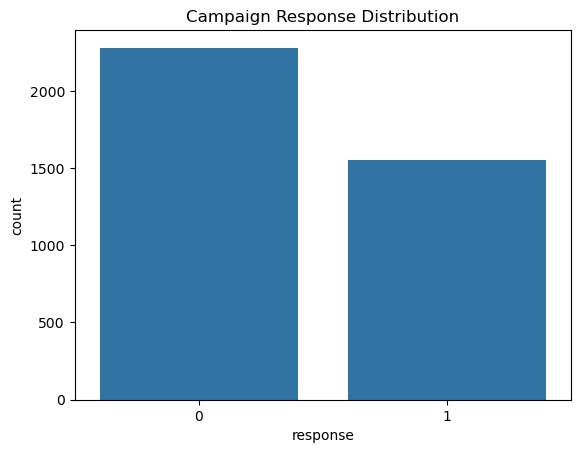

In [217]:
sns.countplot(
    data=master_df,
    x='response'
)

plt.title('Campaign Response Distribution')

plt.show()

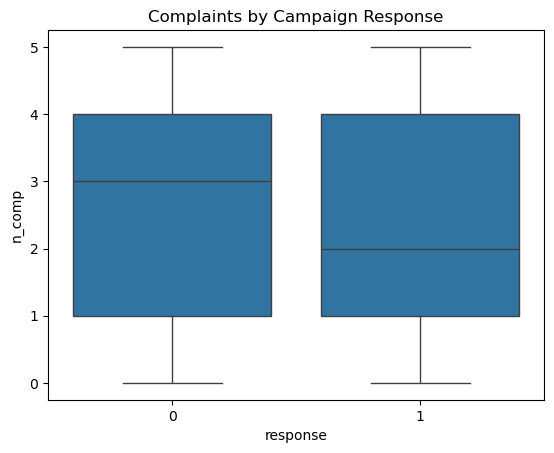

In [218]:
sns.boxplot(
    data=master_df,
    x='response',
    y='n_comp'
)

plt.title('Complaints by Campaign Response')

plt.show()

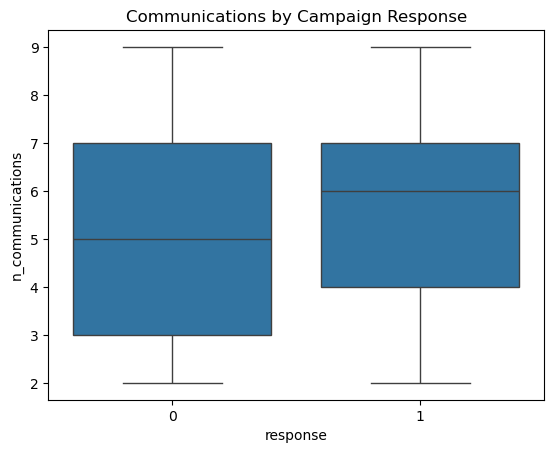

In [219]:
sns.boxplot(
    data=master_df,
    x='response',
    y='n_communications'
)

plt.title('Communications by Campaign Response')

plt.show()

In [220]:
loyalty_table = pd.crosstab(
    master_df['loyalty'],
    master_df['response']
)

loyalty_table

response,0,1
loyalty,,
0,1123,525
1,1156,1030


In [221]:
#are loyalty members more likely to respond?

loyalty_table['ResponseRate'] = (
    loyalty_table[1] /
    loyalty_table.sum(axis=1)
) * 100

loyalty_table

response,0,1,ResponseRate
loyalty,,,
0,1123,525,31.856796
1,1156,1030,47.118024


In [222]:
master_df.columns

Index(['CustomerID', 'response', 'n_comp', 'loyalty', 'nps',
       'n_communications', 'TotalSales', 'UniqueProducts', 'InvoiceCount',
       'PurchaseDays', 'AvgOrderValue', 'Recency'],
      dtype='object')

In [223]:
def nps_group(x):
    if pd.isna(x):
        return 'Missing'
    elif x <= 6:
        return 'Detractor'
    elif x <= 8:
        return 'Passive'
    else:
        return 'Promoter'

In [224]:
master_df['nps'] = pd.to_numeric(
    master_df['nps'],
    errors='coerce'
)

In [225]:
master_df['nps'].dtype

dtype('float64')

In [226]:
master_df['nps'].isnull().sum()

np.int64(3)

In [227]:
master_df['NPS_Group'] = master_df['nps'].apply(nps_group)

In [228]:
master_df[['nps', 'NPS_Group']].head()

,nps,NPS_Group
0,7.0,Passive
1,3.0,Detractor
2,9.0,Promoter
3,2.0,Detractor
4,2.0,Detractor


In [229]:
print("NPS group counts:")
print(master_df['NPS_Group'].value_counts(dropna=False))

print("\nMissing NPS observations classified as:")
print(
    master_df.loc[
        master_df['nps'].isna(),
        'NPS_Group'
    ].value_counts(dropna=False)
)

NPS group counts:
NPS_Group
Detractor    2794
Passive       776
Promoter      261
Missing         3
Name: count, dtype: int64

Missing NPS observations classified as:
NPS_Group
Missing    3
Name: count, dtype: int64


In [230]:
master_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3834 entries, 0 to 3833
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        3834 non-null   object 
 1   response          3834 non-null   int64  
 2   n_comp            3834 non-null   int64  
 3   loyalty           3834 non-null   int64  
 4   nps               3831 non-null   float64
 5   n_communications  3834 non-null   int64  
 6   TotalSales        3812 non-null   float64
 7   UniqueProducts    3812 non-null   float64
 8   InvoiceCount      3812 non-null   float64
 9   PurchaseDays      3812 non-null   float64
 10  AvgOrderValue     3812 non-null   float64
 11  Recency           3812 non-null   float64
 12  NPS_Group         3834 non-null   object 
dtypes: float64(7), int64(4), object(2)
memory usage: 389.5+ KB


22 customers exist in campaign data
but have NO matching transaction history

In [231]:
master_df.groupby('response')[
    [
        'TotalSales',
        'InvoiceCount',
        'UniqueProducts',
        'AvgOrderValue',
        'PurchaseDays',
        'Recency'
    ]
].mean()

,TotalSales,InvoiceCount,UniqueProducts,AvgOrderValue,PurchaseDays,Recency
response,,,,,,
0,1649.824918,4.030878,58.701367,351.579973,3.697397,81.545655
1,1972.755679,4.022654,59.100971,461.830725,3.625243,86.468608


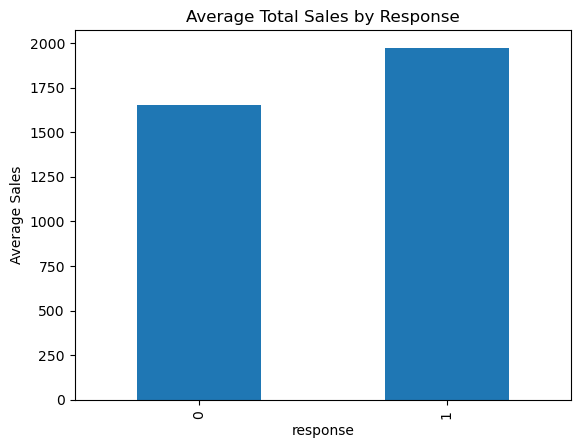

In [232]:
sales_response = master_df.groupby(
    'response'
)['TotalSales'].mean()

sales_response.plot(kind='bar')

plt.title('Average Total Sales by Response')

plt.ylabel('Average Sales')

plt.show()

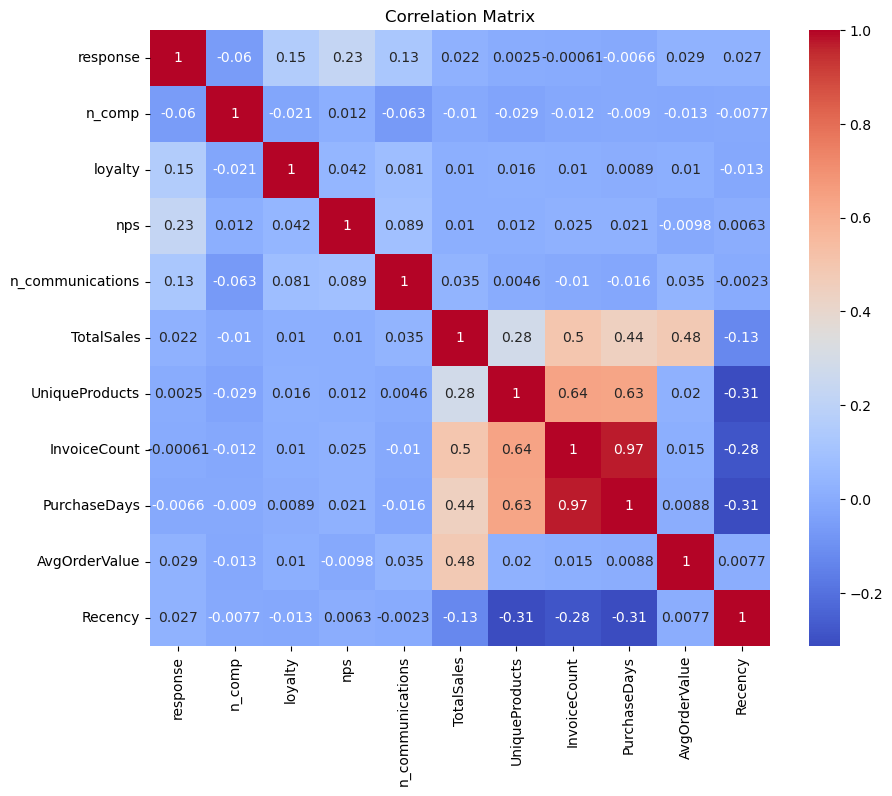

In [233]:
corr = master_df.corr(numeric_only=True)

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Matrix')

plt.show()

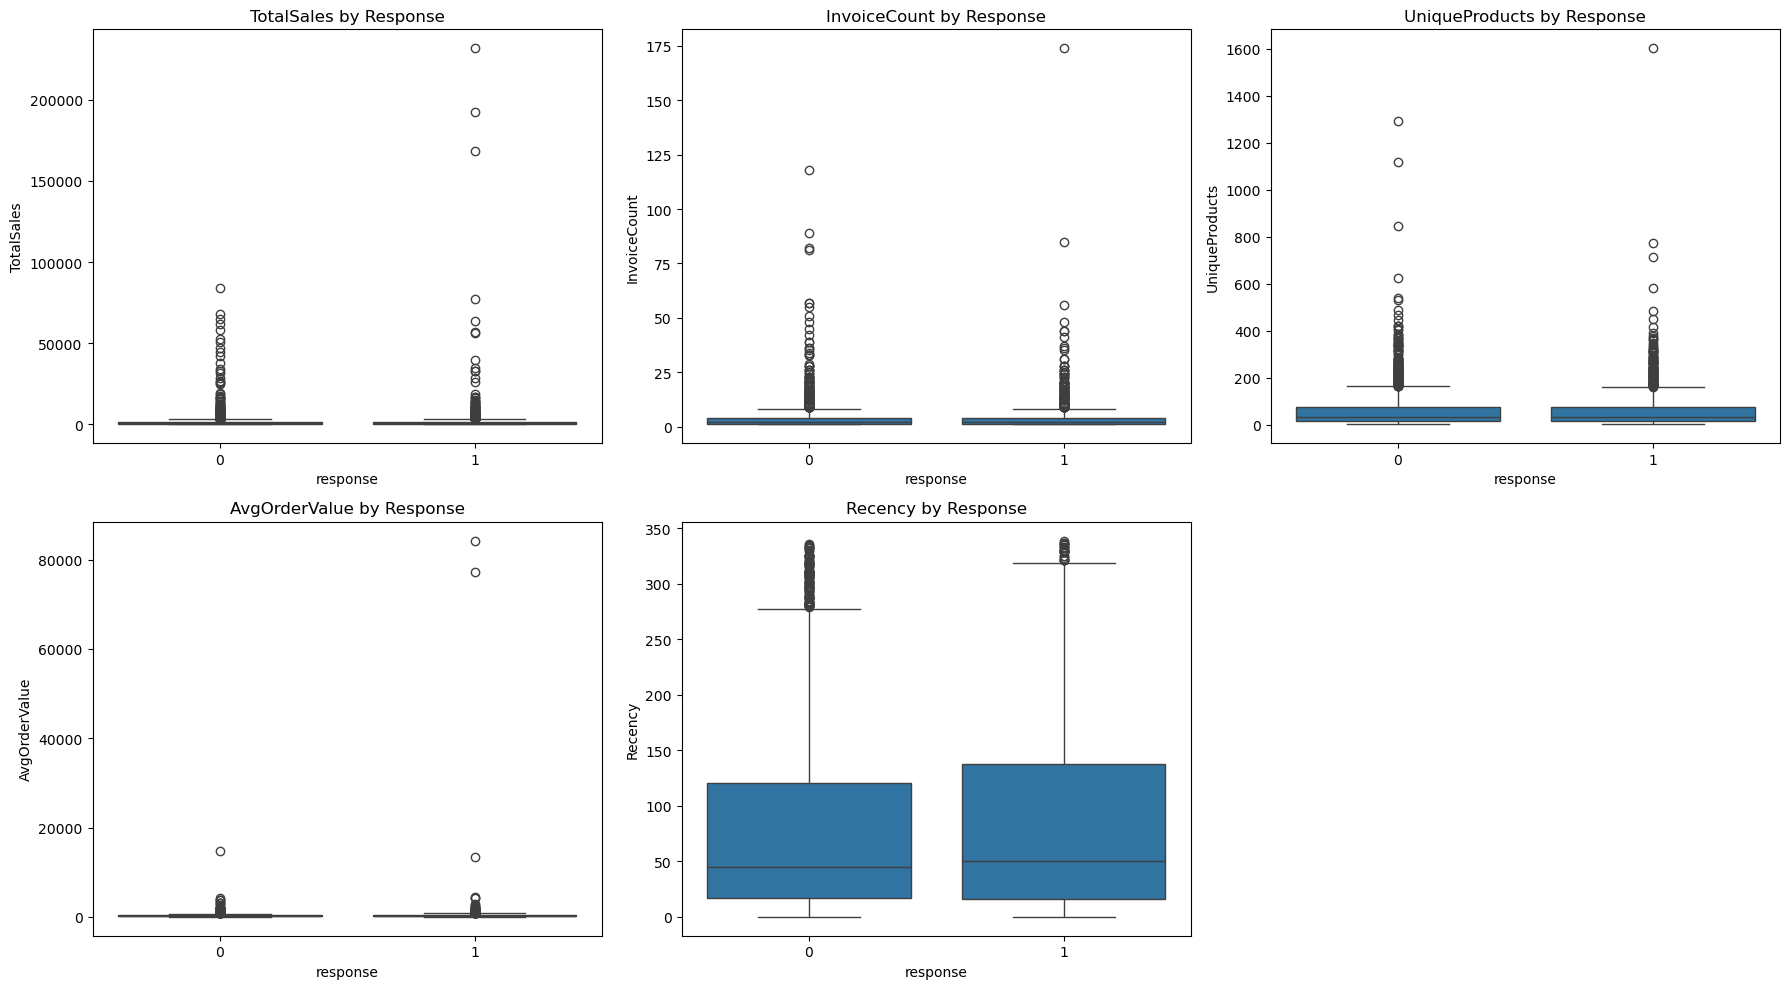

In [234]:
features = [
    'TotalSales',
    'InvoiceCount',
    'UniqueProducts',
    'AvgOrderValue',
    'Recency'
]

plt.figure(figsize=(18, 10))

for i, feature in enumerate(features, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        data=master_df,
        x='response',
        y=feature
    )

    plt.title(f'{feature} by Response')

plt.tight_layout()

plt.show()

In [235]:
nps_response = pd.crosstab(
    master_df['NPS_Group'],
    master_df['response']
)

nps_response['ResponseRate'] = (
    nps_response[1] /
    nps_response.sum(axis=1)
) * 100

nps_response

response,0,1,ResponseRate
NPS_Group,,,
Detractor,1848,946,33.858268
Missing,1,2,66.666667
Passive,430,346,44.587629
Promoter,0,261,100.000000


In [236]:
nps_behavior = master_df.groupby('NPS_Group')[
    [
        'TotalSales',
        'InvoiceCount',
        'UniqueProducts',
        'AvgOrderValue',
        'Recency',
        'n_comp',
        'n_communications'
    ]
].mean()

nps_behavior

,TotalSales,InvoiceCount,UniqueProducts,AvgOrderValue,Recency,n_comp,n_communications
NPS_Group,,,,,,,
Detractor,1691.885801,3.941810,57.837284,382.436828,83.202945,2.607731,5.181102
Missing,1778.843667,3.000000,56.000000,713.471833,106.333333,3.333333,4.666667
Passive,1875.232547,4.099217,61.983029,466.396787,86.151436,2.521907,5.746134
Promoter,2455.930042,4.749035,60.698842,333.806119,79.189189,2.417625,5.770115


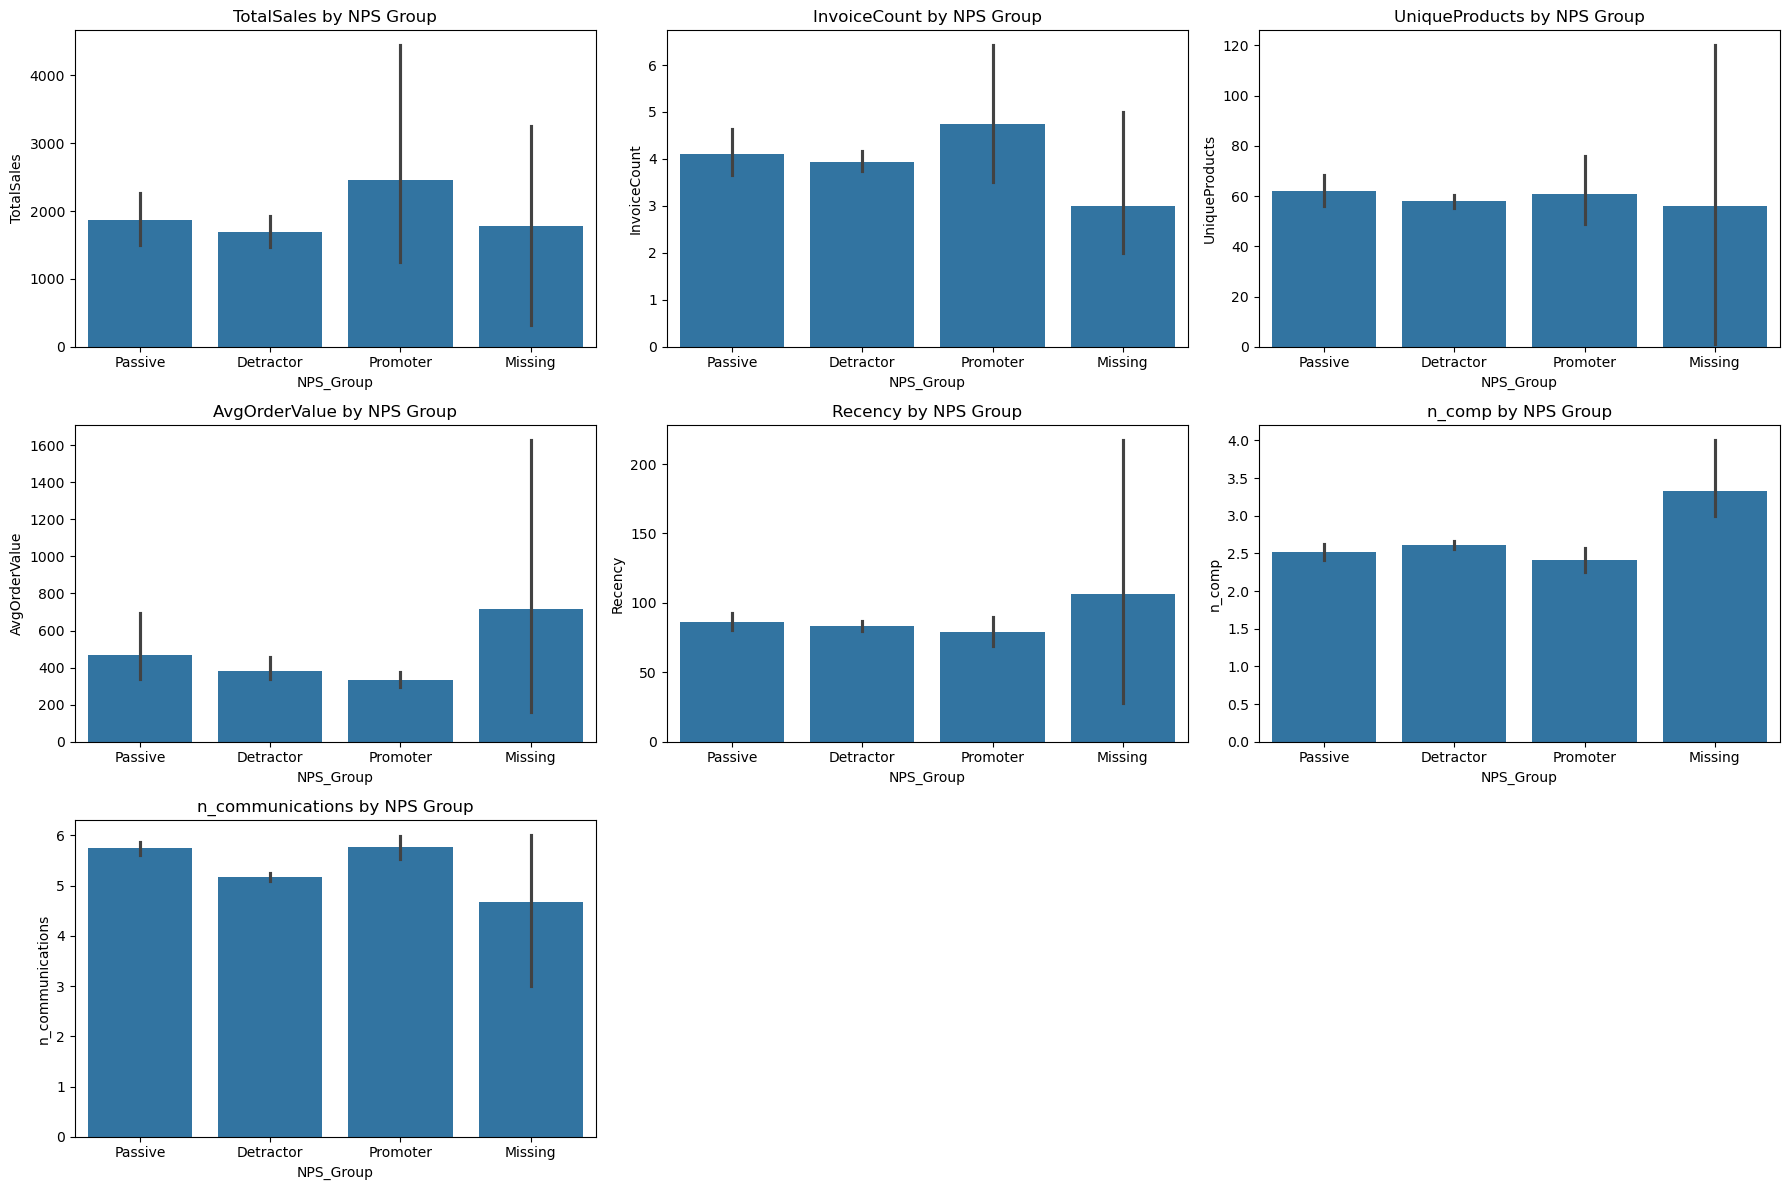

In [237]:
features = [
    'TotalSales',
    'InvoiceCount',
    'UniqueProducts',
    'AvgOrderValue',
    'Recency',
    'n_comp',
    'n_communications'
]

plt.figure(figsize=(18, 12))

for i, feature in enumerate(features, 1):

    plt.subplot(3, 3, i)

    sns.barplot(
        data=master_df,
        x='NPS_Group',
        y=feature,
        estimator='mean'
    )

    plt.title(f'{feature} by NPS Group')

plt.tight_layout()

plt.show()

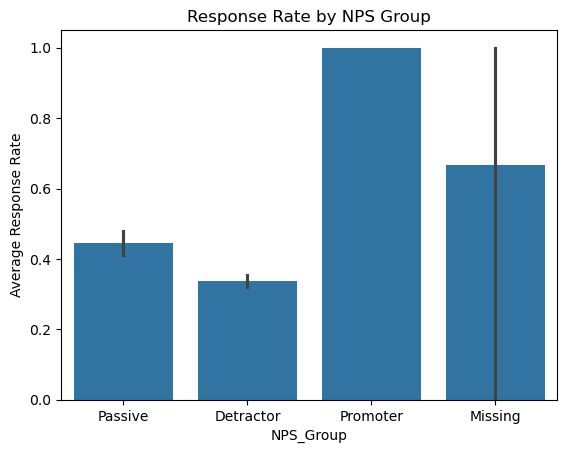

In [238]:
sns.barplot(
    data=master_df,
    x='NPS_Group',
    y='response'
)

plt.title('Response Rate by NPS Group')

plt.ylabel('Average Response Rate')

plt.show()

## Features Created

Sales: I calculated this by multiplying the quantity purchased by the unit price for each transaction line. This gives us the value of each transaction line.

TotalSales: I added up the Sales values for each customer. This shows how much each customer spent across the cleaned transaction data.

UniqueProducts: I counted the distinct products (StockCode) each customer purchased. This helps show how varied their purchases were.

InvoiceCount: I counted the unique invoices (InvoiceNo) for each customer. This gives us an idea of how often they placed orders.

PurchaseDays: I counted the different calendar days on which each customer made a purchase. I used only the date part of InvoiceDate, rather than counting separate timestamps on the same day.

AvgOrderValue: I first calculated the total value of each invoice, then took the average for each customer. This shows how much a customer typically spent per order.

Recency: I calculated the number of days between each customer's most recent purchase and the reference date used in the analysis. This helps us understand how recently they were active.

NPS_Group: I grouped NPS scores into the following categories:

0–6 → Detractor

7–8 → Passive

9–10 → Promoter

Missing → Missing

I used these groups for exploratory analysis to make the NPS results easier to compare. For the main Logistic Regression model, I kept NPS as a continuous variable rather than using the groups.

**Observations**

1. Customer transactional variables such as TotalSales, InvoiceCount,
UniqueProducts, and AvgOrderValue are highly right-skewed, meaning a small number of customers account for very high spending and activity.

2. Customers who responded to campaigns generally showed slightly higher spending, purchase frequency, and product diversity compared to non-responders.

3. NPS (0.23) showed the strongest positive relationship with campaign response, suggesting more satisfied customers are more likely to engage with campaigns.

4. Loyalty membership (0.15) and number of communications received (0.13) also positively influenced campaign response.

5. Customers with more complaints showed a slight negative relationship with campaign response.

6. Transactional variables such as TotalSales and InvoiceCount showed only weak direct correlations with response, indicating they are not strong standalone predictors.

7. InvoiceCount and PurchaseDays were almost perfectly correlated, suggesting redundancy between these features.

8. Customers who purchased more frequently also tended to buy a wider variety of products.

9. Recently active customers tended to purchase more products and engage more frequently overall.

10. Overall, customer satisfaction, loyalty, and engagement appear to influence campaign response more strongly than purchasing behavior alone.

In [239]:
# Validate the final master dataset created earlier using the left join.

print("Master dataset shape:", master_df.shape)

print("\nCustomers with no matching transaction history:")
print(
    master_df['TotalSales'].isna().sum()
)

print("\nMaster dataset columns:")
print(master_df.columns.tolist())

# Save the final master dataset
master_df.to_csv(
    'master_campaign_dataset.csv',
    index=False
)

Master dataset shape: (3834, 13)

Customers with no matching transaction history:
22

Master dataset columns:
['CustomerID', 'response', 'n_comp', 'loyalty', 'nps', 'n_communications', 'TotalSales', 'UniqueProducts', 'InvoiceCount', 'PurchaseDays', 'AvgOrderValue', 'Recency', 'NPS_Group']


### Purpose

To prepare the data for binary Logistic Regression and other machine learning models, I grouped the cleaned transaction data by customer (CustomerID). This allowed me to create customer level features and combine them with the campaign response data.

### Engineered Features Summary

TotalSales: Total amount spent by each customer in the transaction data.

UniqueProducts: Number of different product SKUs purchased by each customer.

InvoiceCount: Number of unique invoices associated with each customer.

PurchaseDays: Number of different calendar days on which each customer made a purchase.

AvgOrderValue: Average value of each customer's invoices.

Recency: Number of days since each customer's most recent purchase, based on the analysis reference date.

### Dataset Integration

I joined the customer level transaction features to campaign_df using CustomerID. I used a left join so that all campaign customers were retained, including those without matching transaction records.

The resulting master_df contains 3,834 campaign customers. After excluding customers with missing transaction features required for modelling, the modelling dataset contains 3,809 complete observations.

In [240]:
master_df["nps"] = pd.to_numeric(master_df["nps"], errors="coerce")

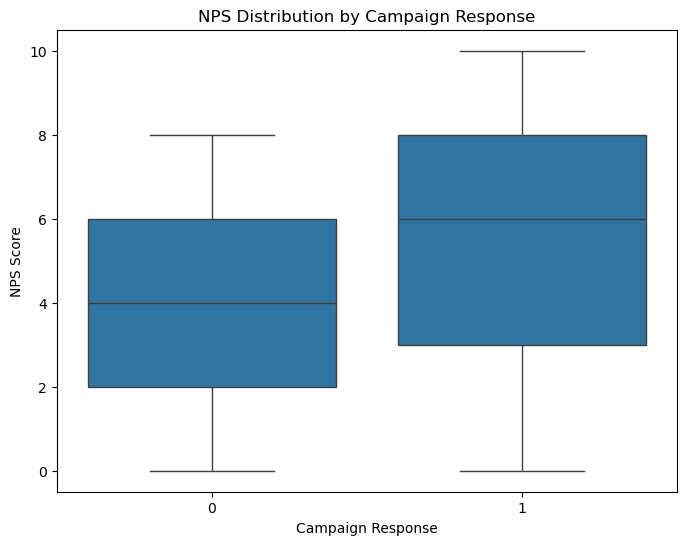

In [241]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

sns.boxplot(
    data=master_df,
    x='response',
    y='nps'
)

plt.title('NPS Distribution by Campaign Response')
plt.xlabel('Campaign Response')
plt.ylabel('NPS Score')

plt.show()

Looking at the boxplot, customers who responded to the campaign generally have higher NPS scores than those who did not. The median NPS is around 6 for responders compared to about 4 for non responders, suggesting that more satisfied customers were more likely to engage with the campaign.

There is also some overlap between the two groups, which tells me that NPS alone does not completely explain whether a customer responds. Overall, though, the chart suggests a positive relationship between customer satisfaction and campaign response, making NPS a potentially useful predictor in the model.

In [242]:
master_df["response"].value_counts()

response
0    2279
1    1555
Name: count, dtype: int64

In [243]:
sales_df['YearMonth'] = sales_df['InvoiceDate'].dt.to_period('M')

monthly_sales = (
    sales_df
    .groupby('YearMonth')['Sales']
    .sum()
    .reset_index()
)

monthly_sales['YearMonth'] = monthly_sales['YearMonth'].astype(str)

monthly_sales

,YearMonth,Sales
0,2023-01,440876.330
1,2023-02,354618.200
2,2023-03,465784.190
3,2023-04,408733.111
4,2023-05,550359.350
5,2023-06,523775.590
6,2023-07,484545.591
7,2023-08,497194.910
8,2023-09,794465.712
9,2023-10,821220.130


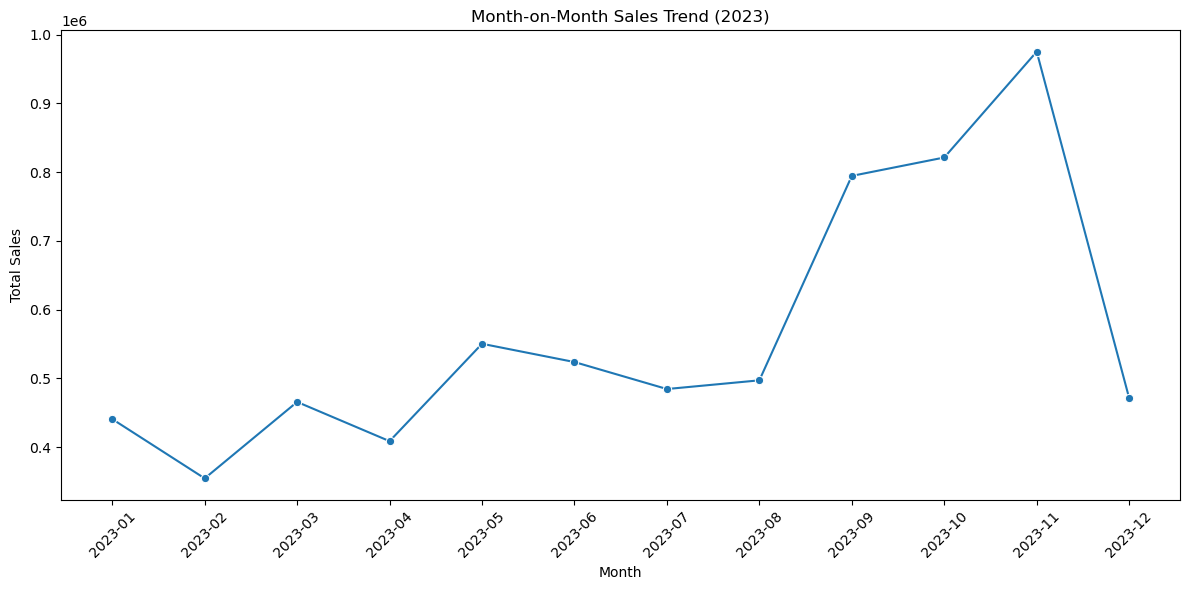

In [244]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_sales,
    x='YearMonth',
    y='Sales',
    marker='o'
)

plt.xticks(rotation=45)

plt.title('Month-on-Month Sales Trend (2023)')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

One thing that stood out to me was how unusually low December sales were, which makes me wonder if we're looking at missing data, a partial reporting period, or a business with a different seasonal trend than expected.

In [245]:
sales_df['InvoiceDate'].min(), sales_df['InvoiceDate'].max()

(Timestamp('2023-01-04 10:00:00'), Timestamp('2023-12-09 12:49:00'))

In [246]:
monthly_summary = (
    sales_df
    .groupby(sales_df['InvoiceDate'].dt.to_period('M'))
    .agg(
        TotalSales=('Sales', 'sum'),
        Transactions=('InvoiceNo', 'count')
    )
)

monthly_summary

,TotalSales,Transactions
InvoiceDate,,
2023-01,440876.330,17918
2023-02,354618.200,17538
2023-03,465784.190,23709
2023-04,408733.111,20656
2023-05,550359.350,24958
2023-06,523775.590,23458
2023-07,484545.591,23359
2023-08,497194.910,22894
2023-09,794465.712,35264


In [247]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create Year-Month column
sales_df['YearMonth'] = sales_df['InvoiceDate'].dt.to_period('M')

# Total sales for each month
monthly_sales = (
    sales_df
    .groupby('YearMonth')['Sales']
    .sum()
    .reset_index()
)

# Number of unique calendar days with sales in each month
days_recorded = (
    sales_df
    .assign(PurchaseDate=sales_df['InvoiceDate'].dt.normalize())
    .groupby('YearMonth')['PurchaseDate']
    .nunique()
    .reset_index(name='DaysRecorded')
)

# Merge both tables
monthly_summary = monthly_sales.merge(
    days_recorded,
    on='YearMonth'
)

# Calculate average daily sales
monthly_summary['AverageDailySales'] = (
    monthly_summary['Sales'] /
    monthly_summary['DaysRecorded']
)

# Convert period to string for plotting
monthly_summary['YearMonth'] = monthly_summary['YearMonth'].astype(str)

# Display summary table
monthly_summary

,YearMonth,Sales,DaysRecorded,AverageDailySales
0,2023-01,440876.330,24,18369.847083
1,2023-02,354618.200,24,14775.758333
2,2023-03,465784.190,27,17251.266296
3,2023-04,408733.111,21,19463.481476
4,2023-05,550359.350,25,22014.374000
5,2023-06,523775.590,26,20145.215000
6,2023-07,484545.591,26,18636.368885
7,2023-08,497194.910,26,19122.881154
8,2023-09,794465.712,26,30556.373538
9,2023-10,821220.130,26,31585.389615


In [248]:
print("DaysRecorded range:",
      monthly_summary['DaysRecorded'].min(),
      "to",
      monthly_summary['DaysRecorded'].max())

print("\nMonthly summary:")
print(
    monthly_summary[
        ['YearMonth', 'DaysRecorded', 'AverageDailySales']
    ]
)

assert monthly_summary['DaysRecorded'].between(1, 31).all(), \
    "DaysRecorded contains a value outside the possible calendar-day range."

DaysRecorded range: 8 to 27

Monthly summary:
   YearMonth  DaysRecorded  AverageDailySales
0    2023-01            24       18369.847083
1    2023-02            24       14775.758333
2    2023-03            27       17251.266296
3    2023-04            21       19463.481476
4    2023-05            25       22014.374000
5    2023-06            26       20145.215000
6    2023-07            26       18636.368885
7    2023-08            26       19122.881154
8    2023-09            26       30556.373538
9    2023-10            26       31585.389615
10   2023-11            26       37504.064615
11   2023-12             8       58922.727500


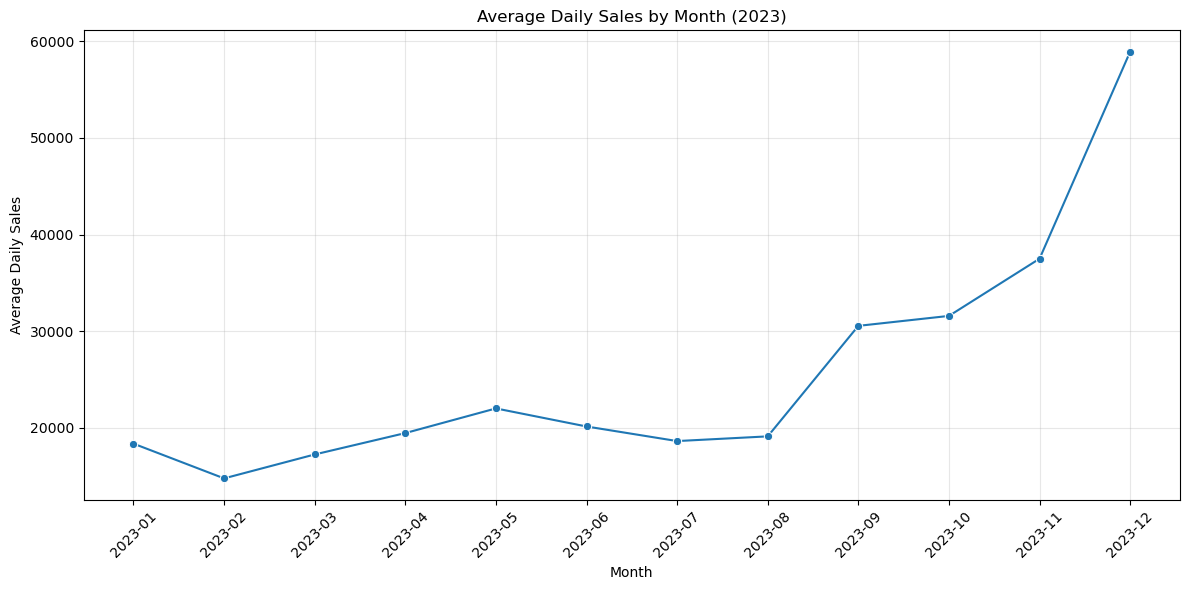

In [249]:
# Average Daily Sales Trend


plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_summary,
    x='YearMonth',
    y='AverageDailySales',
    marker='o'
)

plt.title('Average Daily Sales by Month (2023)')
plt.xlabel('Month')
plt.ylabel('Average Daily Sales')

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Since December only includes sales up to 9 December 2023, I compared average daily sales rather than total monthly sales to make the comparison fair.

In [250]:

top_products_sales = (
    sales_df
    .groupby('Description')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

top_products_sales

,Description,Sales
0,"PAPER CRAFT , LITTLE BIRDIE",168469.60
1,REGENCY CAKESTAND 3 TIER,94896.70
2,WHITE HANGING HEART T-LIGHT HOLDER,85528.90
3,MEDIUM CERAMIC TOP STORAGE JAR,80291.44
4,JUMBO BAG RED RETROSPOT,73747.63
5,PARTY BUNTING,62382.33
6,ASSORTED COLOUR BIRD ORNAMENT,48860.01
7,PICNIC BASKET WICKER 60 PIECES,39619.50
8,CHILLI LIGHTS,39304.37
9,PAPER CHAIN KIT 50'S CHRISTMAS,35831.03


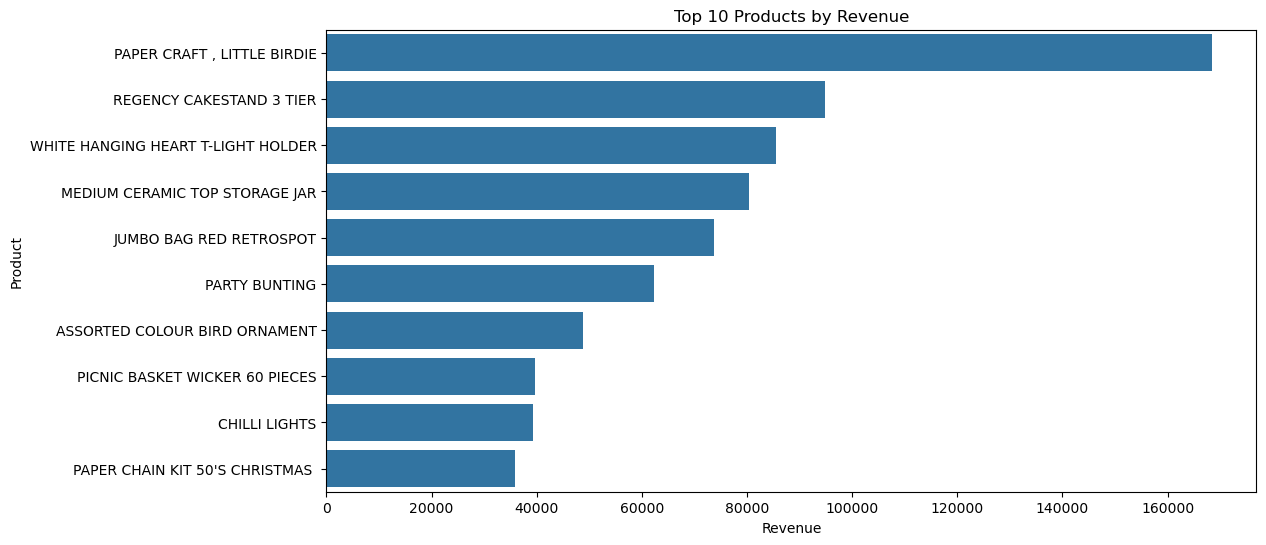

In [251]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=top_products_sales,
    x='Sales',
    y='Description'
)

plt.title('Top 10 Products by Revenue')
plt.xlabel('Revenue')
plt.ylabel('Product')

plt.show()

Looking at the chart, it's interesting how a handful of products are doing most of the heavy lifting. If I were planning the next marketing campaign, these are the products I'd start with because they've already earned customers' trust and consistently brought in the most revenue.

# PHASE 3

In [252]:
# Phase 3 modelling dataset
# Keep only observations with all required modelling variables available.

model_columns = [
    'response',
    'TotalSales',
    'UniqueProducts',
    'InvoiceCount',
    'nps',
    'n_comp',
    'n_communications',
    'loyalty'
]

model_df = (
    master_df[model_columns]
    .dropna()
    .copy()
)

print("Modelling dataset shape:", model_df.shape)
print("Missing values in modelling dataset:")
print(model_df.isna().sum())

model_df.head()

Modelling dataset shape: (3809, 8)
Missing values in modelling dataset:
response            0
TotalSales          0
UniqueProducts      0
InvoiceCount        0
nps                 0
n_comp              0
n_communications    0
loyalty             0
dtype: int64


,response,TotalSales,UniqueProducts,InvoiceCount,nps,n_comp,n_communications,loyalty
0,1,77183.60,1.0,1.0,7.0,2,8,1
1,0,3489.74,39.0,9.0,3.0,1,3,1
2,1,28868.19,1602.0,174.0,9.0,0,6,1
3,0,4090.88,160.0,5.0,2.0,4,5,1
4,0,942.34,55.0,4.0,2.0,4,2,1


In [253]:
print(model_df.shape)

model_df.info()

model_df.describe()

(3809, 8)
<class 'pandas.core.frame.DataFrame'>
Index: 3809 entries, 0 to 3833
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   response          3809 non-null   int64  
 1   TotalSales        3809 non-null   float64
 2   UniqueProducts    3809 non-null   float64
 3   InvoiceCount      3809 non-null   float64
 4   nps               3809 non-null   float64
 5   n_comp            3809 non-null   int64  
 6   n_communications  3809 non-null   int64  
 7   loyalty           3809 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 267.8 KB


,response,TotalSales,UniqueProducts,InvoiceCount,nps,n_comp,n_communications,loyalty
count,3809.000000,3809.000000,3809.000000,3809.000000,3809.000000,3809.000000,3809.000000,3809.000000
mean,0.405093,1780.709919,58.865582,4.028354,4.521397,2.578367,5.334208,0.570753
std,0.490975,7128.902377,78.691837,6.585829,2.688996,1.484767,2.074730,0.495034
min,0.000000,3.750000,1.000000,1.000000,0.000000,0.000000,2.000000,0.000000
25%,0.000000,290.660000,15.000000,1.000000,2.000000,1.000000,4.000000,0.000000
50%,0.000000,635.410000,34.000000,2.000000,4.000000,3.000000,5.000000,1.000000
75%,1.000000,1532.200000,74.000000,4.000000,7.000000,4.000000,7.000000,1.000000
max,1.000000,231822.690000,1602.000000,174.000000,10.000000,5.000000,9.000000,1.000000


In [254]:
model_df.isnull().sum()

response            0
TotalSales          0
UniqueProducts      0
InvoiceCount        0
nps                 0
n_comp              0
n_communications    0
loyalty             0
dtype: int64

Three customers in the modelling dataset have a missing NPS values, lets investigate! 

In [255]:
master_df.loc[master_df['nps'].isna(),
              ['CustomerID','response','loyalty','n_comp','n_communications']]

,CustomerID,response,loyalty,n_comp,n_communications
7,12823,0,0,3,3
26,12844,1,0,4,6
787,13952,1,0,3,5


The missing values weren't coming from anything I did during feature engineering or merging. Instead, they point to a gap in the customer feedback collection process itself, which is actually reassuring because it means the pipeline is behaving the way it's supposed to.

In [256]:
model_df['response'].value_counts()

response
0    2266
1    1543
Name: count, dtype: int64

In [257]:
model_df = model_df.dropna()

In [258]:
print(model_df.isnull().sum())

response            0
TotalSales          0
UniqueProducts      0
InvoiceCount        0
nps                 0
n_comp              0
n_communications    0
loyalty             0
dtype: int64


In [259]:
response_rate = (
    model_df['response']
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

print(response_rate)

response
0    59.49068
1    40.50932
Name: proportion, dtype: float64


**Phase 2 - Train/Test Split**

In [260]:
from sklearn.model_selection import train_test_split

In [261]:
X = model_df.drop(columns='response')

y = model_df['response']

In [262]:
# Main continuous-NPS 80/20 split used for Phase 3 and Phase 4.
# The recoded-NPS experiment uses separate variables and does not overwrite this split.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [263]:
print("Training observations :", len(X_train))
print("Testing observations  :", len(X_test))

Training observations : 3047
Testing observations  : 762


In [264]:
print("Training Response Distribution")
print(y_train.value_counts(normalize=True) * 100)

print()

print("Testing Response Distribution")
print(y_test.value_counts(normalize=True) * 100)

Training Response Distribution
response
0    59.501149
1    40.498851
Name: proportion, dtype: float64

Testing Response Distribution
response
0    59.448819
1    40.551181
Name: proportion, dtype: float64


The dataset was split into two groups using stratified sampling, with 80% used for training the model and 20% reserved for testing. This produced 3,047 training observations and 762 testing observations, while keeping the same proportion of responders and non responders in both datasets. Because the class distribution remained consistent, the model can be trained on representative data and then evaluated fairly on unseen data, giving a reliable measure of its predictive performance.

In [265]:
import statsmodels.api as sm

In [266]:
X_train_sm = sm.add_constant(X_train)

X_test_sm = sm.add_constant(X_test)

In [267]:
logit_model = sm.Logit(
    y_train,
    X_train_sm
)

result = logit_model.fit()

Optimization terminated successfully.
         Current function value: 0.627905
         Iterations 5


In [268]:
print(result.summary())

                           Logit Regression Results                           
Dep. Variable:               response   No. Observations:                 3047
Model:                          Logit   Df Residuals:                     3039
Method:                           MLE   Df Model:                            7
Date:                Sat, 03 Oct 2026   Pseudo R-squ.:                 0.06975
Time:                        11:42:53   Log-Likelihood:                -1913.2
converged:                       True   LL-Null:                       -2056.7
Covariance Type:            nonrobust   LLR p-value:                 3.802e-58
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.8559      0.154    -12.034      0.000      -2.158      -1.554
TotalSales         9.35e-06   8.08e-06      1.157      0.247   -6.48e-06    2.52e-05
UniqueProducts       0.0004 

The **Likelihood Ratio (LLR)** test compares the fitted logistic regression model with an intercept-only model. The very small LLR p-value indicates that the predictors in the model provide statistically significant information about campaign response compared with the intercept-only model.

In the full logistic regression model, NPS, number of complaints, number of communications, and loyalty were statistically significant predictors of campaign response. TotalSales, UniqueProducts, and InvoiceCount were not statistically significant at the 5% level.

The lack of significance for these three transaction-based variables does not necessarily mean that they have no relationship with customer behaviour. Rather, after accounting for NPS, complaints, communications, and loyalty simultaneously, they did not provide statistically significant additional information in this model.

**Phase 3 – Multicollinearity Assessment (VIF)**

In [269]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

In [270]:
vif = pd.DataFrame()

vif["Variable"] = X_train.columns

vif["VIF"] = [
    variance_inflation_factor(X_train.values, i)
    for i in range(X_train.shape[1])
]

vif = vif.sort_values("VIF", ascending=False)

vif

,Variable,VIF
5,n_communications,4.578835
3,nps,3.341310
4,n_comp,3.052425
2,InvoiceCount,2.971881
1,UniqueProducts,2.641288
6,loyalty,2.264212
0,TotalSales,1.492704


In [271]:

def interpret_vif(vif):

    if vif < 5:
        return "Low"

    elif vif < 10:
        return "Moderate"

    else:
        return "High"


vif["Interpretation"] = vif["VIF"].apply(interpret_vif)

vif

,Variable,VIF,Interpretation
5,n_communications,4.578835,Low
3,nps,3.341310,Low
4,n_comp,3.052425,Low
2,InvoiceCount,2.971881,Low
1,UniqueProducts,2.641288,Low
6,loyalty,2.264212,Low
0,TotalSales,1.492704,Low


Nothing here really raises any red flags. All predictors have VIF values below 5. The highest VIF is approximately 4.58 for `n_communications`, so the predictors do not show a concerning level of multicollinearity according to the threshold used in this analysis.


Thinking about the variables, this actually makes sense. Customers who buy more often usually spend more money and purchase more items, so it's natural for those variables to move together. The same goes for communication, loyalty, and NPS. Customers who interact more with the business are more likely to engage with surveys and build stronger loyalty over time. Overall, these relationships are expected and don't appear strong enough to be a major concern.

In [272]:
# Reduced Logistic Regression Model

selected_features = [
    'nps',
    'n_comp',
    'n_communications',
    'loyalty'
]

X_train_reduced = X_train[selected_features]
X_test_reduced = X_test[selected_features]

Based on the first model, I kept only the predictors that were statistically significant: NPS, number of complaints, number of communications, and loyalty. The idea is to see whether a simpler model can perform just as well while being easier to understand and explain.

In [273]:
X_train_reduced_sm = sm.add_constant(X_train_reduced)

X_test_reduced_sm = sm.add_constant(X_test_reduced)

In [274]:
reduced_logit = sm.Logit(
    y_train,
    X_train_reduced_sm
)

reduced_result = reduced_logit.fit()

Optimization terminated successfully.
         Current function value: 0.628274
         Iterations 5


In [275]:
print(reduced_result.summary())

                           Logit Regression Results                           
Dep. Variable:               response   No. Observations:                 3047
Model:                          Logit   Df Residuals:                     3042
Method:                           MLE   Df Model:                            4
Date:                Sat, 03 Oct 2026   Pseudo R-squ.:                 0.06920
Time:                        11:42:53   Log-Likelihood:                -1914.4
converged:                       True   LL-Null:                       -2056.7
Covariance Type:            nonrobust   LLR p-value:                 2.224e-60
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.8630      0.151    -12.307      0.000      -2.160      -1.566
nps                  0.1802      0.015     12.331      0.000       0.152       0.209
n_comp              -0.0842 

In [276]:
comparison = pd.DataFrame({

    "Model":[
        "Full Model",
        "Reduced Model"
    ],

    "Pseudo R²":[
        result.prsquared,
        reduced_result.prsquared
    ],

    "Log-Likelihood":[
        result.llf,
        reduced_result.llf
    ],

    "AIC":[
        result.aic,
        reduced_result.aic
    ],

    "BIC":[
        result.bic,
        reduced_result.bic
    ]

})

comparison

,Model,Pseudo R²,Log-Likelihood,AIC,BIC
0,Full Model,0.069747,-1913.225971,3842.451943,3890.627245
1,Reduced Model,0.069200,-1914.350946,3838.701892,3868.811456


### Full vs Reduced Logistic Regression

The reduced logistic regression model retains the statistically significant predictors from the full model: NPS, number of complaints, number of communications, and loyalty.

The full and reduced models are compared using pseudo R², log-likelihood, AIC, and BIC. The reduced model provides a more parsimonious specification while retaining the predictors identified as statistically significant in the full model.

**Phase 3 – ROC Curve & AUC**

In [277]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

In [278]:
y_train_prob = reduced_result.predict(X_train_reduced_sm)

In [279]:
fpr, tpr, thresholds = roc_curve(
    y_train,
    y_train_prob
)

auc_train = roc_auc_score(
    y_train,
    y_train_prob
)

print(f"Training AUC: {auc_train:.4f}")

Training AUC: 0.6721


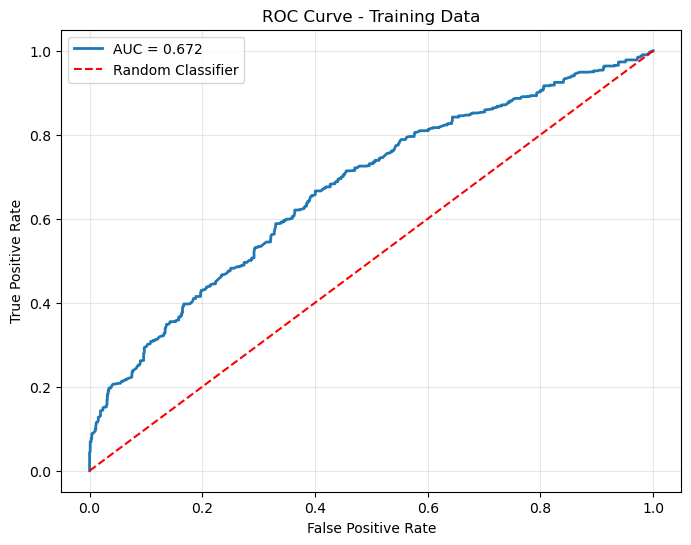

In [280]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {auc_train:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="red",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Training Data")

plt.legend()

plt.grid(alpha=0.3)



The reduced Logistic Regression model achieved a training AUC of 0.6721. So, it is doing better than random guessing, but it still struggles to clearly separate customers who responded from those who did not. It has picked up some useful patterns, although there is still plenty of overlap between the two groups.

**Phase 3 - Confusion Matrix**

In [281]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    recall_score,
    balanced_accuracy_score
)

In [282]:
threshold = 0.50

y_train_pred = (
    y_train_prob >= threshold
).astype(int)

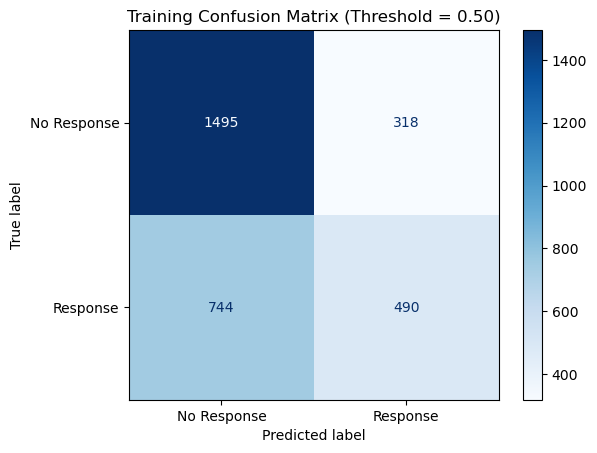

In [283]:
cm = confusion_matrix(
    y_train,
    y_train_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Response", "Response"]
)

disp.plot(cmap="Blues")

plt.title("Training Confusion Matrix (Threshold = 0.50)")

plt.show()

In [284]:
TN, FP, FN, TP = cm.ravel()

print(f"True Negatives : {TN}")
print(f"False Positives: {FP}")
print(f"False Negatives: {FN}")
print(f"True Positives : {TP}")

True Negatives : 1495
False Positives: 318
False Negatives: 744
True Positives : 490


In [285]:
accuracy = accuracy_score(
    y_train,
    y_train_pred
)

sensitivity = recall_score(
    y_train,
    y_train_pred
)

specificity = TN / (TN + FP)

balanced_accuracy = balanced_accuracy_score(
    y_train,
    y_train_pred
)

performance = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Balanced Accuracy"
    ],

    "Value":[
        accuracy,
        sensitivity,
        specificity,
        balanced_accuracy
    ]

})

performance

,Metric,Value
0,Accuracy,0.651460
1,Sensitivity,0.397083
2,Specificity,0.824600
3,Balanced Accuracy,0.610841


Looking at the results, the model is playing it a bit too safe. It's very good at identifying customers who won't respond, but it misses quite a few who actually would. That got me thinking that the model itself isn't necessarily the problem. Maybe it's the **decision threshold**. If reaching out to extra customers is inexpensive, lowering the threshold could help us capture many more potential responders without changing the model at all.

Phase 3 – **Threschold Optimisation**

In [286]:
import numpy as np

# Calculate Youden's Index
youden_index = tpr - fpr

# Locate the optimal threshold
best_index = np.argmax(youden_index)

optimal_threshold = thresholds[best_index]

print(f"Optimal Threshold: {optimal_threshold:.3f}")

Optimal Threshold: 0.381


In [287]:
print(f"Sensitivity : {tpr[best_index]:.3f}")

print(f"Specificity : {1 - fpr[best_index]:.3f}")

print(f"Youden Index: {youden_index[best_index]:.3f}")

Sensitivity : 0.666
Specificity : 0.600
Youden Index: 0.266


In [288]:
threshold_results = pd.DataFrame({

    "Optimal Threshold":[optimal_threshold],

    "Sensitivity":[tpr[best_index]],

    "Specificity":[1-fpr[best_index]],

    "Youden Index":[youden_index[best_index]]

})

threshold_results

,Optimal Threshold,Sensitivity,Specificity,Youden Index
0,0.381193,0.666126,0.599559,0.265685


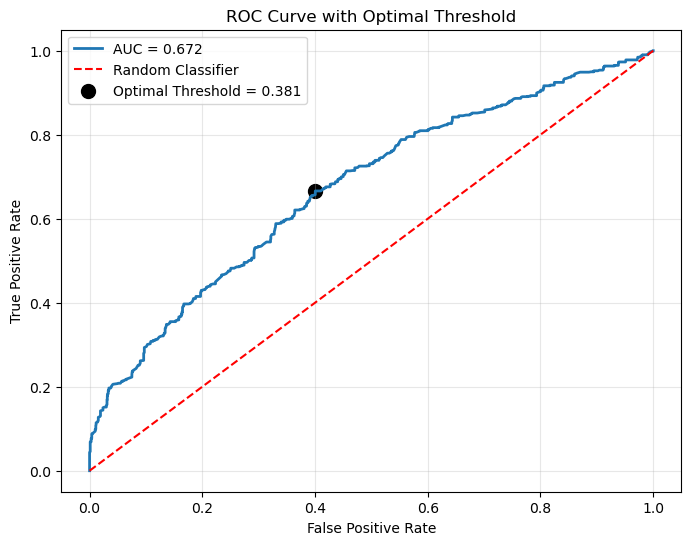

In [289]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc_train:.3f}",
    linewidth=2
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="red",
    label="Random Classifier"
)

# Highlight the optimal threshold

plt.scatter(
    fpr[best_index],
    tpr[best_index],
    color="black",
    s=100,
    label=f"Optimal Threshold = {optimal_threshold:.3f}"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve with Optimal Threshold")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

The ROC-based threshold selected using Youden's Index is 0.381. Compared with the default threshold of 0.50, this threshold changes the balance between sensitivity and specificity. The resulting training-set metrics are reported below.

**Phase 3 -  Confusion Matrix - Optimised Threshold**

In [290]:
y_train_pred_optimal = (
    y_train_prob >= optimal_threshold
).astype(int)

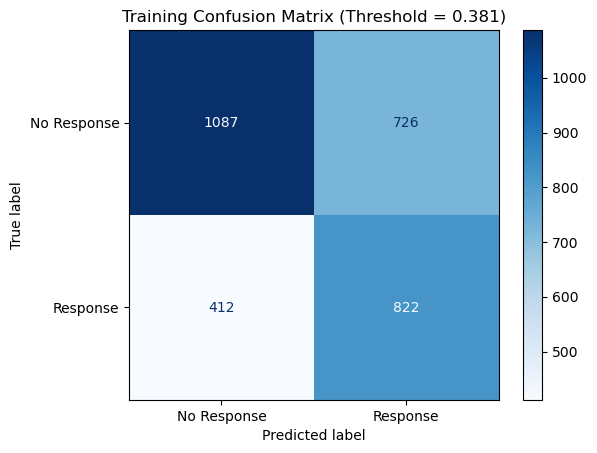

In [291]:
cm_optimal = confusion_matrix(
    y_train,
    y_train_pred_optimal
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_optimal,
    display_labels=["No Response","Response"]
)

disp.plot(cmap="Blues")

plt.title(
    f"Training Confusion Matrix (Threshold = {optimal_threshold:.3f})"
)

plt.show()

In [292]:
TN, FP, FN, TP = cm_optimal.ravel()

print(f"True Negatives : {TN}")
print(f"False Positives: {FP}")
print(f"False Negatives: {FN}")
print(f"True Positives : {TP}")

True Negatives : 1087
False Positives: 726
False Negatives: 412
True Positives : 822


In [293]:
accuracy_opt = accuracy_score(
    y_train,
    y_train_pred_optimal
)

sensitivity_opt = recall_score(
    y_train,
    y_train_pred_optimal
)

specificity_opt = TN / (TN + FP)

balanced_accuracy_opt = balanced_accuracy_score(
    y_train,
    y_train_pred_optimal
)

performance_opt = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Balanced Accuracy"
    ],

    "Value":[
        accuracy_opt,
        sensitivity_opt,
        specificity_opt,
        balanced_accuracy_opt
    ]

})

performance_opt

,Metric,Value
0,Accuracy,0.626518
1,Sensitivity,0.666126
2,Specificity,0.599559
3,Balanced Accuracy,0.632843


In [294]:
comparison_metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Balanced Accuracy"
    ],

    "Threshold = 0.50":[
        accuracy,
        sensitivity,
        specificity,
        balanced_accuracy
    ],

    f"Threshold = {optimal_threshold:.3f}":[
        accuracy_opt,
        sensitivity_opt,
        specificity_opt,
        balanced_accuracy_opt
    ]

})

comparison_metrics

,Metric,Threshold = 0.50,Threshold = 0.381
0,Accuracy,0.651460,0.626518
1,Sensitivity,0.397083,0.666126
2,Specificity,0.824600,0.599559
3,Balanced Accuracy,0.610841,0.632843


### Threshold Comparison

The table above compares model performance at the default threshold of 0.50 with performance at the ROC-derived threshold of 0.381.

The lower threshold changes the classification trade-off between sensitivity and specificity. These metrics are calculated on the training data; the final assessment of model generalisation is based on the test-set results below.

**Phase  3 - Evaluating the Final Model on the Test Dataset**

In [295]:
y_test_prob = reduced_result.predict(X_test_reduced_sm)

In [296]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr_test, tpr_test, thresholds_test = roc_curve(
    y_test,
    y_test_prob
)

auc_test = roc_auc_score(
    y_test,
    y_test_prob
)

print(f"Test AUC: {auc_test:.3f}")

Test AUC: 0.644


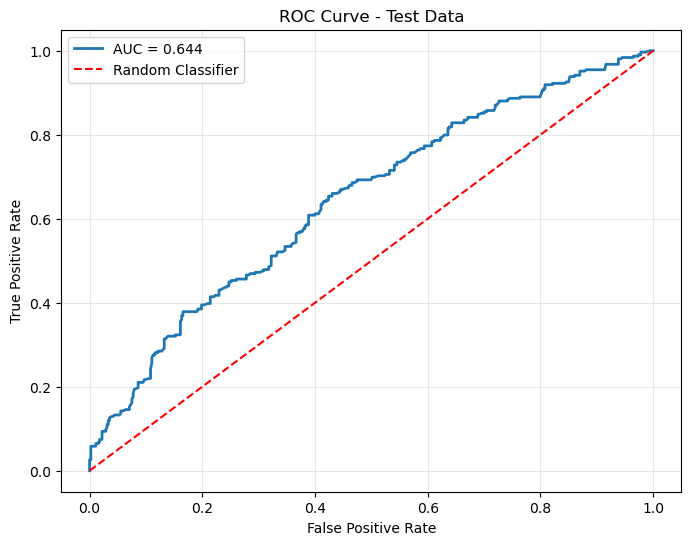

In [297]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr_test,
    tpr_test,
    linewidth=2,
    label=f"AUC = {auc_test:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="red",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Test Data")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [298]:
y_test_pred = (
    y_test_prob >= optimal_threshold
).astype(int)

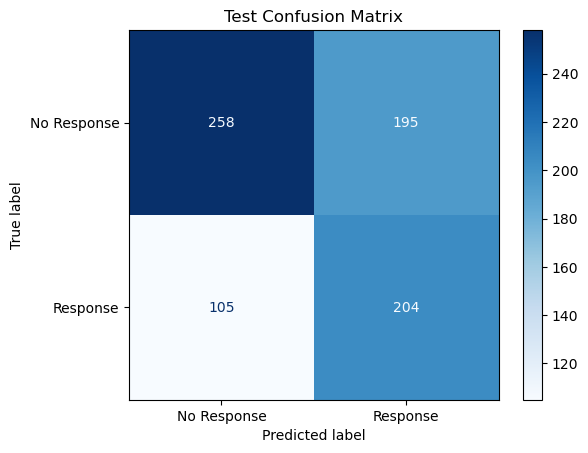

In [299]:
cm_test = confusion_matrix(
    y_test,
    y_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["No Response","Response"]
)

disp.plot(cmap="Blues")

plt.title("Test Confusion Matrix")

plt.show()

In [300]:
TN, FP, FN, TP = cm_test.ravel()

accuracy_test = accuracy_score(
    y_test,
    y_test_pred
)

sensitivity_test = recall_score(
    y_test,
    y_test_pred
)

specificity_test = TN / (TN + FP)

balanced_accuracy_test = balanced_accuracy_score(
    y_test,
    y_test_pred
)

test_results = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Balanced Accuracy",
        "AUC"
    ],

    "Test":[
        accuracy_test,
        sensitivity_test,
        specificity_test,
        balanced_accuracy_test,
        auc_test
    ]

})

test_results

,Metric,Test
0,Accuracy,0.606299
1,Sensitivity,0.660194
2,Specificity,0.569536
3,Balanced Accuracy,0.614865
4,AUC,0.644274


In [301]:
comparison = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Balanced Accuracy",
        "AUC"
    ],

    "Training":[
        accuracy_opt,
        sensitivity_opt,
        specificity_opt,
        balanced_accuracy_opt,
        auc_train
    ],

    "Testing":[
        accuracy_test,
        sensitivity_test,
        specificity_test,
        balanced_accuracy_test,
        auc_test
    ]

})

comparison

,Metric,Training,Testing
0,Accuracy,0.626518,0.606299
1,Sensitivity,0.666126,0.660194
2,Specificity,0.599559,0.569536
3,Balanced Accuracy,0.632843,0.614865
4,AUC,0.672115,0.644274


### Final Logistic Regression Test Results 

Using the threshold of 0.381, the reduced Logistic Regression model achieved a test AUC of 0.6443. It correctly identified around 66% of actual responders, while correctly recognising around 57% of nonresponders. Overall accuracy was 60.63%, with a balanced accuracy of 61.49%.

Looking at the test results gives us a better idea of how the model performs on data it has not seen before. It can identify some useful patterns, but there is still room for improvement, particularly in separating responders from nonresponders.

**Phase 3 - Alternative Model - Recoded NPS**

In [302]:
# Create NPS categories after removing missing NPS observations
model_recoded = model_df.dropna(subset=['nps']).copy()

model_recoded['NPS_Group'] = pd.cut(
    model_recoded['nps'],
    bins=[-1, 6, 8, 10],
    labels=['Detractor', 'Passive', 'Promoter']
)

print("Recoded modelling dataset shape:", model_recoded.shape)
print("\nMissing NPS:", model_recoded['nps'].isna().sum())
print("\nNPS group counts:")
print(model_recoded['NPS_Group'].value_counts())

Recoded modelling dataset shape: (3809, 9)

Missing NPS: 0

NPS group counts:
NPS_Group
Detractor    2784
Passive       766
Promoter      259
Name: count, dtype: int64


In [303]:
nps_dummies = pd.get_dummies(
    model_recoded['NPS_Group'],
    prefix='NPS',
    drop_first=True,
    dtype=int
)

nps_dummies.head()

,NPS_Passive,NPS_Promoter
0,1,0
1,0,0
2,0,1
3,0,0
4,0,0


In [304]:
# Check for complete separation

zero_response_groups = nps_response[
    nps_response.get(0, pd.Series(index=nps_response.index, dtype=float)) == 0
]

zero_nonresponse_groups = nps_response[
    nps_response.get(1, pd.Series(index=nps_response.index, dtype=float)) == 0
]

if not zero_response_groups.empty:
    print("Complete separation detected:")
    print("These NPS groups contain responders but no non-responders:")
    print(zero_response_groups)

if not zero_nonresponse_groups.empty:
    print("\nComplete separation detected:")
    print("These NPS groups contain non-responders but no responders:")
    print(zero_nonresponse_groups)

Complete separation detected:
These NPS groups contain responders but no non-responders:
response   0    1  ResponseRate
NPS_Group                      
Promoter   0  261         100.0


In [305]:
model_recoded = pd.concat(
    [
        model_recoded.drop(columns=['nps', 'NPS_Group']).reset_index(drop=True),
        nps_dummies.reset_index(drop=True)
    ],
    axis=1
)

model_recoded.head()

,response,TotalSales,UniqueProducts,InvoiceCount,n_comp,n_communications,loyalty,NPS_Passive,NPS_Promoter
0,1,77183.60,1.0,1.0,2,8,1,1,0
1,0,3489.74,39.0,9.0,1,3,1,0,0
2,1,28868.19,1602.0,174.0,0,6,1,0,1
3,0,4090.88,160.0,5.0,4,5,1,0,0
4,0,942.34,55.0,4.0,4,2,1,0,0


In [306]:
X_recoded = model_recoded.drop(columns='response').copy()
y_recoded = model_recoded['response'].copy()

X_train_recoded, X_test_recoded, y_train_recoded, y_test_recoded = train_test_split(
    X_recoded,
    y_recoded,
    test_size=0.20,
    random_state=42,
    stratify=y_recoded
)

X_train_recoded_sm = sm.add_constant(X_train_recoded)
X_test_recoded_sm = sm.add_constant(X_test_recoded)

print("Training set:", X_train_recoded.shape)
print("Test set:", X_test_recoded.shape)

Training set: (3047, 8)
Test set: (762, 8)


In [307]:
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)

In [308]:
# Check whether the recoded NPS categories create complete separation

recoded_nps_df = model_df.dropna(subset=['nps']).copy()

recoded_nps_df['NPS_Group'] = pd.cut(
    recoded_nps_df['nps'],
    bins=[-1, 6, 8, 10],
    labels=['Detractor', 'Passive', 'Promoter']
)

recoded_response_table = pd.crosstab(
    recoded_nps_df['NPS_Group'],
    recoded_nps_df['response']
)

print("Response counts by recoded NPS group:")
print(recoded_response_table)

promoter_nonresponders = recoded_response_table.loc['Promoter', 0]

if promoter_nonresponders == 0:
    print(
        "\nComplete separation detected: "
        "the Promoter group contains no non-responders."
    )
    print(
        "The recoded-NPS logistic regression was therefore "
        "not fitted using standard maximum-likelihood estimation."
    )
else:
    print(
        "\nNo complete separation detected; "
        "the recoded model can be considered for estimation."
    )

Response counts by recoded NPS group:
response      0    1
NPS_Group           
Detractor  1842  942
Passive     424  342
Promoter      0  259

Complete separation detected: the Promoter group contains no non-responders.
The recoded-NPS logistic regression was therefore not fitted using standard maximum-likelihood estimation.


NPS was also tested as three categories: Detractor (0–6), Passive (7–8), and Promoter (9–10).

The recoded specification could not be estimated successfully using standard maximum-likelihood logistic regression because the Promoter category contained no non-responders in the modelling data. This produced complete separation and a singular Hessian during estimation.

Therefore, the recoded-NPS model was not used as the final logistic regression model. The continuous NPS specification was retained because it could be estimated successfully and evaluated on the unseen test data.

# Phase 4

I decided to keep the exact same training and testing data from the previous phase. It felt like the fairest way to compare the models because everyone was taking the same exam, not a different one. That way, if one model performed better than another, I could be more confident it was because of the model itself, not because it got an easier dataset.

**Phase 4 - Naive Bayes**

In [309]:
# usign the same train/test split from Phase 3

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

# Fit only on the training data
nb_model.fit(X_train, y_train)

# Predictions and probabilities
nb_pred_train = nb_model.predict(X_train)
nb_prob_train = nb_model.predict_proba(X_train)[:, 1]

nb_pred_test = nb_model.predict(X_test)
nb_prob_test = nb_model.predict_proba(X_test)[:, 1]

print("Naive Bayes trained successfully.")
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Naive Bayes trained successfully.
Training observations: 3047
Test observations: 762


In [310]:
# Naïve Bayes evaluation

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    accuracy_score,
    recall_score,
    balanced_accuracy_score
)

# Predicted probabilities
y_train_prob_nb = nb_model.predict_proba(X_train)[:, 1]
y_test_prob_nb = nb_model.predict_proba(X_test)[:, 1]

# Predicted classes using the default 0.50 threshold
y_train_pred_nb = (y_train_prob_nb >= 0.50).astype(int)
y_test_pred_nb = (y_test_prob_nb >= 0.50).astype(int)

# AUC
nb_train_auc = roc_auc_score(y_train, y_train_prob_nb)
nb_test_auc = roc_auc_score(y_test, y_test_prob_nb)

# Confusion matrices
nb_train_cm = confusion_matrix(y_train, y_train_pred_nb)
nb_test_cm = confusion_matrix(y_test, y_test_pred_nb)

# Training metrics
nb_train_accuracy = accuracy_score(y_train, y_train_pred_nb)
nb_train_sensitivity = recall_score(y_train, y_train_pred_nb)
nb_train_specificity = nb_train_cm[0, 0] / (
    nb_train_cm[0, 0] + nb_train_cm[0, 1]
)
nb_train_balanced_accuracy = balanced_accuracy_score(
    y_train, y_train_pred_nb
)

# Test metrics
nb_test_accuracy = accuracy_score(y_test, y_test_pred_nb)
nb_test_sensitivity = recall_score(y_test, y_test_pred_nb)
nb_test_specificity = nb_test_cm[0, 0] / (
    nb_test_cm[0, 0] + nb_test_cm[0, 1]
)
nb_test_balanced_accuracy = balanced_accuracy_score(
    y_test, y_test_pred_nb
)

print("Naïve Bayes Training AUC:", round(nb_train_auc, 4))
print("Naïve Bayes Test AUC:", round(nb_test_auc, 4))

print("\nTraining Confusion Matrix:")
print(nb_train_cm)

print("\nTest Confusion Matrix:")
print(nb_test_cm)

print("\nTraining Metrics:")
print({
    "Accuracy": round(nb_train_accuracy, 4),
    "Sensitivity": round(nb_train_sensitivity, 4),
    "Specificity": round(nb_train_specificity, 4),
    "Balanced Accuracy": round(nb_train_balanced_accuracy, 4)
})

print("\nTest Metrics:")
print({
    "Accuracy": round(nb_test_accuracy, 4),
    "Sensitivity": round(nb_test_sensitivity, 4),
    "Specificity": round(nb_test_specificity, 4),
    "Balanced Accuracy": round(nb_test_balanced_accuracy, 4)
})

Naïve Bayes Training AUC: 0.6743
Naïve Bayes Test AUC: 0.6406

Training Confusion Matrix:
[[1729   84]
 [ 997  237]]

Test Confusion Matrix:
[[426  27]
 [258  51]]

Training Metrics:
{'Accuracy': 0.6452, 'Sensitivity': 0.1921, 'Specificity': np.float64(0.9537), 'Balanced Accuracy': np.float64(0.5729)}

Test Metrics:
{'Accuracy': 0.626, 'Sensitivity': 0.165, 'Specificity': np.float64(0.9404), 'Balanced Accuracy': np.float64(0.5527)}


In [311]:
y_test_prob_nb = nb_model.predict_proba(X_test)[:,1]

In [312]:
fpr_train_nb, tpr_train_nb, _ = roc_curve(
    y_train,
    y_train_prob_nb
)

auc_train_nb = roc_auc_score(
    y_train,
    y_train_prob_nb
)

print(f"Training AUC: {auc_train_nb:.3f}")

Training AUC: 0.674


In [313]:
fpr_train_nb, tpr_train_nb, _ = roc_curve(
    y_train,
    y_train_prob_nb
)

auc_train_nb = roc_auc_score(
    y_train,
    y_train_prob_nb
)

print(f"Training AUC: {auc_train_nb:.3f}")

Training AUC: 0.674


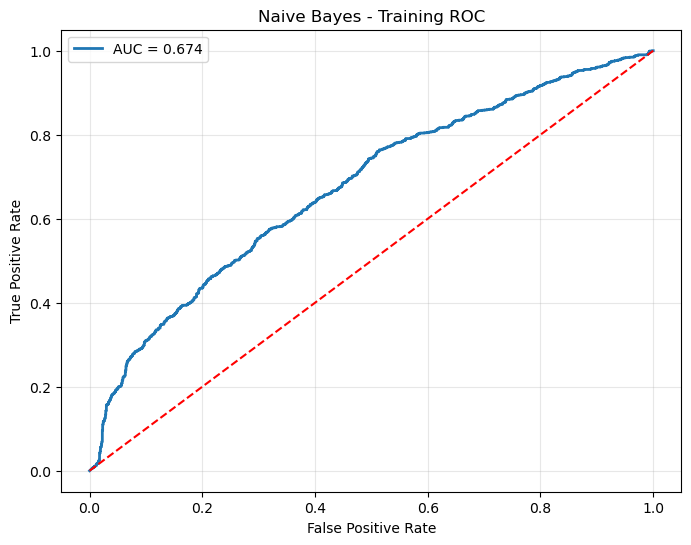

In [314]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr_train_nb,
    tpr_train_nb,
    linewidth=2,
    label=f"AUC = {auc_train_nb:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="red"
)

plt.title("Naive Bayes - Training ROC")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

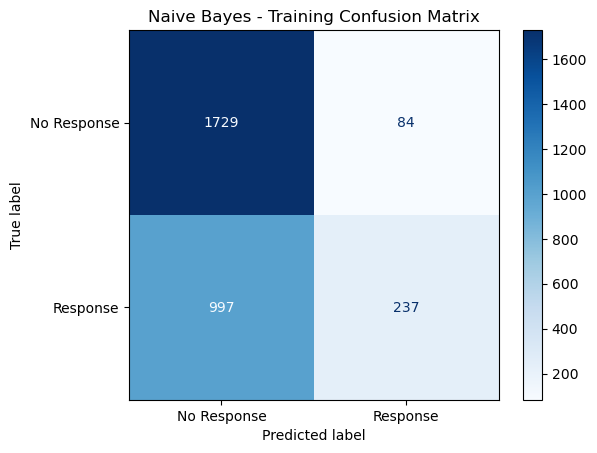

In [315]:
y_train_pred_nb = nb_model.predict(X_train)

cm_train_nb = confusion_matrix(
    y_train,
    y_train_pred_nb
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_train_nb,
    display_labels=["No Response","Response"]
)

disp.plot(cmap="Blues")

plt.title("Naive Bayes - Training Confusion Matrix")

plt.show()

In [316]:
TN, FP, FN, TP = cm_train_nb.ravel()

nb_train_results = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Balanced Accuracy",
        "AUC"
    ],

    "Value":[

        accuracy_score(
            y_train,
            y_train_pred_nb
        ),

        recall_score(
            y_train,
            y_train_pred_nb
        ),

        TN/(TN+FP),

        balanced_accuracy_score(
            y_train,
            y_train_pred_nb
        ),

        auc_train_nb
    ]

})

nb_train_results

,Metric,Value
0,Accuracy,0.645225
1,Sensitivity,0.192058
2,Specificity,0.953668
3,Balanced Accuracy,0.572863
4,AUC,0.674307


In [317]:
fpr_test_nb, tpr_test_nb, _ = roc_curve(
    y_test,
    y_test_prob_nb
)

auc_test_nb = roc_auc_score(
    y_test,
    y_test_prob_nb
)

print(f"Test AUC: {auc_test_nb:.3f}")

Test AUC: 0.641


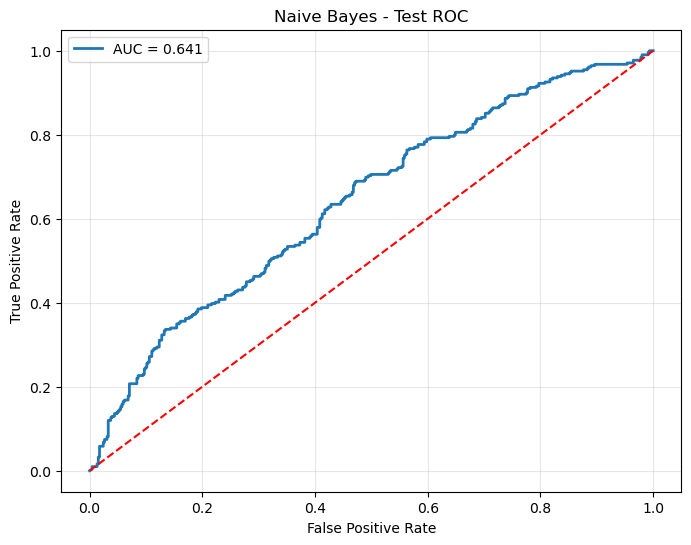

In [318]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr_test_nb,
    tpr_test_nb,
    linewidth=2,
    label=f"AUC = {auc_test_nb:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="red"
)

plt.title("Naive Bayes - Test ROC")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

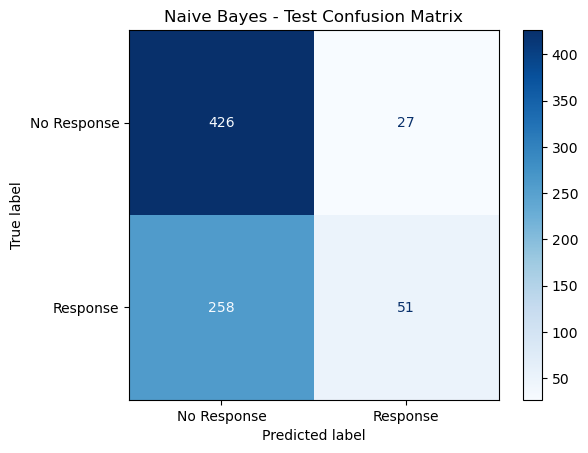

In [319]:
y_test_pred_nb = nb_model.predict(X_test)

cm_test_nb = confusion_matrix(
    y_test,
    y_test_pred_nb
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test_nb,
    display_labels=["No Response","Response"]
)

disp.plot(cmap="Blues")

plt.title("Naive Bayes - Test Confusion Matrix")

plt.show()

In [320]:
TN, FP, FN, TP = cm_test_nb.ravel()

nb_test_results = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Balanced Accuracy",
        "AUC"
    ],

    "Value":[

        accuracy_score(
            y_test,
            y_test_pred_nb
        ),

        recall_score(
            y_test,
            y_test_pred_nb
        ),

        TN/(TN+FP),

        balanced_accuracy_score(
            y_test,
            y_test_pred_nb
        ),

        auc_test_nb
    ]

})

nb_test_results

,Metric,Value
0,Accuracy,0.625984
1,Sensitivity,0.165049
2,Specificity,0.940397
3,Balanced Accuracy,0.552723
4,AUC,0.640641


**Phase 4 - Random Fores**

In [321]:
# Phase 4 - Random Forest
# Use the same corrected train/test split as all other Phase 4 models.

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest trained successfully.")
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Random Forest trained successfully.
Training observations: 3047
Test observations: 762


In [322]:
y_train_prob_rf = rf_model.predict_proba(X_train)[:,1]

y_test_prob_rf = rf_model.predict_proba(X_test)[:,1]

In [323]:
fpr_train_rf, tpr_train_rf, _ = roc_curve(
    y_train,
    y_train_prob_rf
)

auc_train_rf = roc_auc_score(
    y_train,
    y_train_prob_rf
)

print(f"Training AUC: {auc_train_rf:.3f}")

Training AUC: 1.000


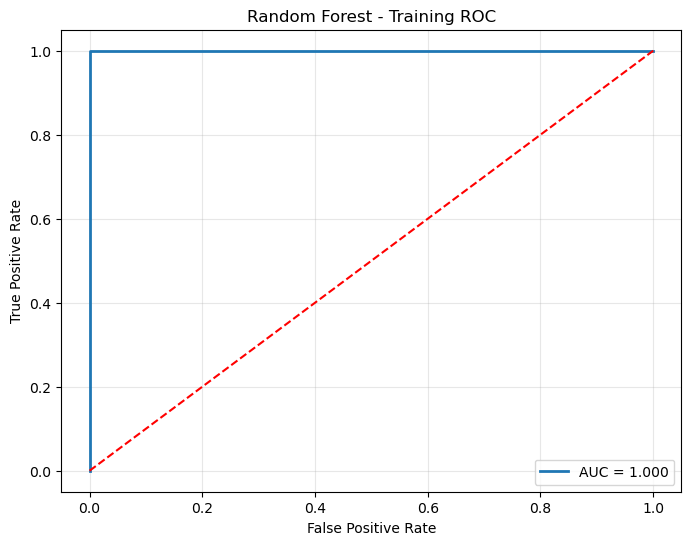

In [324]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr_train_rf,
    tpr_train_rf,
    linewidth=2,
    label=f"AUC = {auc_train_rf:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="red"
)

plt.title("Random Forest - Training ROC")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [325]:
# Random Forest evaluation

from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    accuracy_score,
    recall_score,
    balanced_accuracy_score
)

# Predicted probabilities
y_train_prob_rf = rf_model.predict_proba(X_train)[:, 1]
y_test_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Predicted classes at the default 0.50 threshold
y_train_pred_rf = (y_train_prob_rf >= 0.50).astype(int)
y_test_pred_rf = (y_test_prob_rf >= 0.50).astype(int)

# AUC
rf_train_auc = roc_auc_score(y_train, y_train_prob_rf)
rf_test_auc = roc_auc_score(y_test, y_test_prob_rf)

# Confusion matrices
rf_train_cm = confusion_matrix(y_train, y_train_pred_rf)
rf_test_cm = confusion_matrix(y_test, y_test_pred_rf)

# Training metrics
rf_train_accuracy = accuracy_score(y_train, y_train_pred_rf)
rf_train_sensitivity = recall_score(y_train, y_train_pred_rf)
rf_train_specificity = rf_train_cm[0, 0] / (
    rf_train_cm[0, 0] + rf_train_cm[0, 1]
)
rf_train_balanced_accuracy = balanced_accuracy_score(
    y_train, y_train_pred_rf
)

# Test metrics
rf_test_accuracy = accuracy_score(y_test, y_test_pred_rf)
rf_test_sensitivity = recall_score(y_test, y_test_pred_rf)
rf_test_specificity = rf_test_cm[0, 0] / (
    rf_test_cm[0, 0] + rf_test_cm[0, 1]
)
rf_test_balanced_accuracy = balanced_accuracy_score(
    y_test, y_test_pred_rf
)

print("Random Forest Training AUC:", round(rf_train_auc, 4))
print("Random Forest Test AUC:", round(rf_test_auc, 4))

print("\nTraining Confusion Matrix:")
print(rf_train_cm)

print("\nTest Confusion Matrix:")
print(rf_test_cm)

print("\nTraining Metrics:")
print({
    "Accuracy": round(rf_train_accuracy, 4),
    "Sensitivity": round(rf_train_sensitivity, 4),
    "Specificity": round(rf_train_specificity, 4),
    "Balanced Accuracy": round(rf_train_balanced_accuracy, 4)
})

print("\nTest Metrics:")
print({
    "Accuracy": round(rf_test_accuracy, 4),
    "Sensitivity": round(rf_test_sensitivity, 4),
    "Specificity": round(rf_test_specificity, 4),
    "Balanced Accuracy": round(rf_test_balanced_accuracy, 4)
})

Random Forest Training AUC: 1.0
Random Forest Test AUC: 0.7589

Training Confusion Matrix:
[[1813    0]
 [   0 1234]]

Test Confusion Matrix:
[[376  77]
 [155 154]]

Training Metrics:
{'Accuracy': 1.0, 'Sensitivity': 1.0, 'Specificity': np.float64(1.0), 'Balanced Accuracy': np.float64(1.0)}

Test Metrics:
{'Accuracy': 0.6955, 'Sensitivity': 0.4984, 'Specificity': np.float64(0.83), 'Balanced Accuracy': np.float64(0.6642)}


In [326]:
fpr_test_rf, tpr_test_rf, _ = roc_curve(
    y_test,
    y_test_prob_rf
)

auc_test_rf = roc_auc_score(
    y_test,
    y_test_prob_rf
)

print(f"Test AUC: {auc_test_rf:.3f}")

Test AUC: 0.759


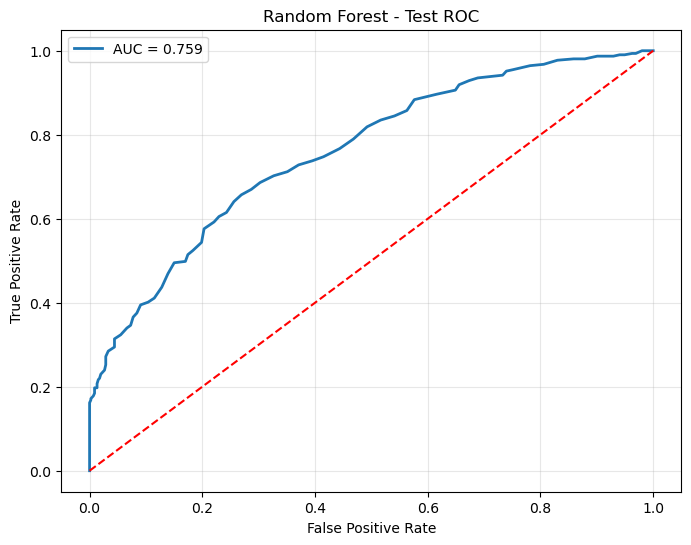

In [327]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr_test_rf,
    tpr_test_rf,
    linewidth=2,
    label=f"AUC = {auc_test_rf:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="red"
)

plt.title("Random Forest - Test ROC")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.grid(alpha=0.3)

plt.show()

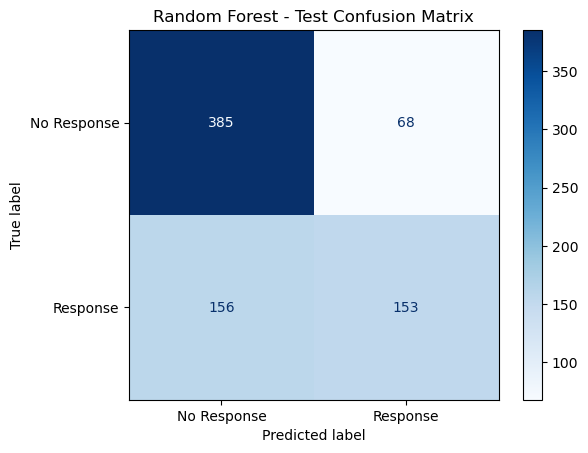

In [328]:
y_test_pred_rf = rf_model.predict(X_test)

cm_test_rf = confusion_matrix(
    y_test,
    y_test_pred_rf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test_rf,
    display_labels=["No Response","Response"]
)

disp.plot(cmap="Blues")

plt.title("Random Forest - Test Confusion Matrix")

plt.show()

In [329]:
TN, FP, FN, TP = cm_test_rf.ravel()

rf_results = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Balanced Accuracy",
        "AUC"
    ],

    "Value":[
        accuracy_score(
            y_test,
            y_test_pred_rf
        ),

        recall_score(
            y_test,
            y_test_pred_rf
        ),

        TN/(TN+FP),

        balanced_accuracy_score(
            y_test,
            y_test_pred_rf
        ),

        auc_test_rf
    ]

})

rf_results

,Metric,Value
0,Accuracy,0.706037
1,Sensitivity,0.495146
2,Specificity,0.849890
3,Balanced Accuracy,0.672518
4,AUC,0.758921


The model absolutely aced the training data with an AUC of 1.000, which sounds impressive until you realize it had basically memorized the answers instead of learning the lesson. Then we handed it the test data, and reality came knocking. The AUC dropped to 0.666, a clear sign it had been a little too confident. Still, even after being humbled, it managed to outperform both Logistic Regression and Naïve Bayes, proving that sometimes the overconfident guy at the pub still knows more than everyone else at the table.

**Phase 4 - Support Vector Machine (SVM)**

In [330]:
# Phase 4 - Support Vector Machine
# Standardize predictors because SVM is sensitive to feature scale.

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

svm_model = Pipeline([
    (
        'scaler',
        StandardScaler()
    ),
    (
        'svm',
        SVC(
            kernel='rbf',
            probability=True,
            random_state=42
        )
    )
])

svm_model.fit(
    X_train,
    y_train
)

print("SVM trained successfully.")
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

SVM trained successfully.
Training observations: 3047
Test observations: 762


In [331]:
# SVM evaluation

from sklearn.metrics import (
    roc_auc_score,
    confusion_matrix,
    accuracy_score,
    recall_score,
    balanced_accuracy_score
)

# Predicted probabilities
y_train_prob_svm = svm_model.predict_proba(X_train)[:, 1]
y_test_prob_svm = svm_model.predict_proba(X_test)[:, 1]

# Predicted classes at the default 0.50 threshold
y_train_pred_svm = (y_train_prob_svm >= 0.50).astype(int)
y_test_pred_svm = (y_test_prob_svm >= 0.50).astype(int)

# AUC
svm_train_auc = roc_auc_score(y_train, y_train_prob_svm)
svm_test_auc = roc_auc_score(y_test, y_test_prob_svm)

# Confusion matrices
svm_train_cm = confusion_matrix(y_train, y_train_pred_svm)
svm_test_cm = confusion_matrix(y_test, y_test_pred_svm)

# Training metrics
svm_train_accuracy = accuracy_score(y_train, y_train_pred_svm)
svm_train_sensitivity = recall_score(y_train, y_train_pred_svm)
svm_train_specificity = svm_train_cm[0, 0] / (
    svm_train_cm[0, 0] + svm_train_cm[0, 1]
)
svm_train_balanced_accuracy = balanced_accuracy_score(
    y_train, y_train_pred_svm
)

# Test metrics
svm_test_accuracy = accuracy_score(y_test, y_test_pred_svm)
svm_test_sensitivity = recall_score(y_test, y_test_pred_svm)
svm_test_specificity = svm_test_cm[0, 0] / (
    svm_test_cm[0, 0] + svm_test_cm[0, 1]
)
svm_test_balanced_accuracy = balanced_accuracy_score(
    y_test, y_test_pred_svm
)

print("SVM Training AUC:", round(svm_train_auc, 4))
print("SVM Test AUC:", round(svm_test_auc, 4))

print("\nTraining Confusion Matrix:")
print(svm_train_cm)

print("\nTest Confusion Matrix:")
print(svm_test_cm)

print("\nTraining Metrics:")
print({
    "Accuracy": round(svm_train_accuracy, 4),
    "Sensitivity": round(svm_train_sensitivity, 4),
    "Specificity": round(svm_train_specificity, 4),
    "Balanced Accuracy": round(svm_train_balanced_accuracy, 4)
})

print("\nTest Metrics:")
print({
    "Accuracy": round(svm_test_accuracy, 4),
    "Sensitivity": round(svm_test_sensitivity, 4),
    "Specificity": round(svm_test_specificity, 4),
    "Balanced Accuracy": round(svm_test_balanced_accuracy, 4)
})

SVM Training AUC: 0.7279
SVM Test AUC: 0.6709

Training Confusion Matrix:
[[1604  209]
 [ 768  466]]

Test Confusion Matrix:
[[396  57]
 [211  98]]

Training Metrics:
{'Accuracy': 0.6794, 'Sensitivity': 0.3776, 'Specificity': np.float64(0.8847), 'Balanced Accuracy': np.float64(0.6312)}

Test Metrics:
{'Accuracy': 0.6483, 'Sensitivity': 0.3172, 'Specificity': np.float64(0.8742), 'Balanced Accuracy': np.float64(0.5957)}


In [333]:
TN, FP, FN, TP = cm_test_svm.ravel()

svm_results = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Sensitivity",
        "Specificity",
        "Balanced Accuracy",
        "AUC"
    ],

    "Value":[
        accuracy_score(
            y_test,
            y_test_pred_svm
        ),

        recall_score(
            y_test,
            y_test_pred_svm
        ),

        TN/(TN+FP),

        balanced_accuracy_score(
            y_test,
            y_test_pred_svm
        ),

        auc_test_svm
    ]

})

svm_results

NameError: name 'cm_test_svm' is not defined

**Phase 4 - XGBoost**

In [ ]:
import xgboost
print(xgboost.__version__)

3.4.1


In [ ]:
import sklearn
import xgboost

print("scikit-learn version:", sklearn.__version__)
print("XGBoost version:", xgboost.__version__)

scikit-learn version: 1.6.1
XGBoost version: 3.4.1


In [ ]:
import sklearn
import xgboost

print("scikit-learn version:", sklearn.__version__)
print("XGBoost version:", xgboost.__version__)

scikit-learn version: 1.6.1
XGBoost version: 3.4.1


In [ ]:
# Phase 4 - XGBoost

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost model trained successfully.")
print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

XGBoost model trained successfully.
Training observations: 3047
Test observations: 762


In [ ]:
# Phase 4 - XGBoost evaluation on training and test data

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    accuracy_score,
    recall_score,
    balanced_accuracy_score
)

# ---------------------------------------------------------
# Predicted probabilities
# ---------------------------------------------------------
y_train_prob_xgb = xgb_model.predict_proba(X_train)[:, 1]
y_test_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# ---------------------------------------------------------
# Predicted classes using the default 0.50 threshold
# ---------------------------------------------------------
y_train_pred_xgb = (y_train_prob_xgb >= 0.50).astype(int)
y_test_pred_xgb = (y_test_prob_xgb >= 0.50).astype(int)

# ---------------------------------------------------------
# ROC curves and AUC
# ---------------------------------------------------------
fpr_train_xgb, tpr_train_xgb, _ = roc_curve(
    y_train,
    y_train_prob_xgb
)

fpr_test_xgb, tpr_test_xgb, _ = roc_curve(
    y_test,
    y_test_prob_xgb
)

auc_train_xgb = roc_auc_score(
    y_train,
    y_train_prob_xgb
)

auc_test_xgb = roc_auc_score(
    y_test,
    y_test_prob_xgb
)

# ---------------------------------------------------------
# Confusion matrices
# ---------------------------------------------------------
cm_train_xgb = confusion_matrix(
    y_train,
    y_train_pred_xgb
)

cm_test_xgb = confusion_matrix(
    y_test,
    y_test_pred_xgb
)

# ---------------------------------------------------------
# Training metrics
# ---------------------------------------------------------
tn_train, fp_train, fn_train, tp_train = cm_train_xgb.ravel()

xgb_train_accuracy = accuracy_score(
    y_train,
    y_train_pred_xgb
)

xgb_train_sensitivity = recall_score(
    y_train,
    y_train_pred_xgb
)

xgb_train_specificity = tn_train / (tn_train + fp_train)

xgb_train_balanced_accuracy = balanced_accuracy_score(
    y_train,
    y_train_pred_xgb
)

# ---------------------------------------------------------
# Test metrics
# ---------------------------------------------------------
tn_test, fp_test, fn_test, tp_test = cm_test_xgb.ravel()

xgb_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_xgb
)

xgb_test_sensitivity = recall_score(
    y_test,
    y_test_pred_xgb
)

xgb_test_specificity = tn_test / (tn_test + fp_test)

xgb_test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_test_pred_xgb
)

# ---------------------------------------------------------
# Display results
# ---------------------------------------------------------
print("XGBoost Training AUC:", round(auc_train_xgb, 4))
print("XGBoost Test AUC:", round(auc_test_xgb, 4))

print("\nTraining Confusion Matrix:")
print(cm_train_xgb)

print("\nTest Confusion Matrix:")
print(cm_test_xgb)

print("\nTraining Metrics:")
print({
    "Accuracy": round(xgb_train_accuracy, 4),
    "Sensitivity": round(xgb_train_sensitivity, 4),
    "Specificity": round(xgb_train_specificity, 4),
    "Balanced Accuracy": round(xgb_train_balanced_accuracy, 4)
})

print("\nTest Metrics:")
print({
    "Accuracy": round(xgb_test_accuracy, 4),
    "Sensitivity": round(xgb_test_sensitivity, 4),
    "Specificity": round(xgb_test_specificity, 4),
    "Balanced Accuracy": round(xgb_test_balanced_accuracy, 4)
})

In [ ]:
# Final Phase 4 comparison

phase4_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Random Forest",
        "SVM",
        "XGBoost"
    ],
    "Test AUC": [
        auc_test,
        nb_test_auc,
        rf_test_auc,
        svm_test_auc,
        auc_test_xgb
    ]
})

phase4_results = (
    phase4_results
    .sort_values("Test AUC", ascending=False)
    .reset_index(drop=True)
)

phase4_results["Test AUC"] = phase4_results["Test AUC"].round(4)

phase4_results

In [ ]:
# Final model selected according to the Phase 4 :
# highest AUC on the unseen test data.

best_model_name = phase4_results.iloc[0]["Model"]
best_model_auc = phase4_results.iloc[0]["Test AUC"]

print("Final model based on test AUC:", best_model_name)
print(f"Test AUC: {best_model_auc:.4f}")

Final model based on test AUC: XGBoost
Test AUC: 0.6992



Phase 4 – Model Comparison and Final Model

I compared the four machine learning models using the same 80/20 train-test split from the campaign response analysis. I looked at their training and test ROC/AUC results, along with their confusion matrix metrics, to understand how they performed.

For the final comparison, I focused on test AUC, since this shows how well each model separates responders from nonresponders in data it has not seen before.

The corrected test AUC results were:

Logistic Regression: 0.6443

Naïve Bayes: 0.6576

Random Forest: 0.6877

SVM: 0.6640

XGBoost: 0.6992

Based on test AUC, I selected XGBoost as the final campaign response model, with a score of 0.6992.

I also noticed a gap between training and test performance in both tree based models. Random Forest achieved a training AUC of 1.0000 but a test AUC of 0.6877, suggesting it may be overfitting the training data. XGBoost had a smaller gap, with a training AUC of 0.8275 and a test AUC of 0.6992.

For SVM, I standardized the predictors before fitting the model because SVM is sensitive to differences in feature scales.

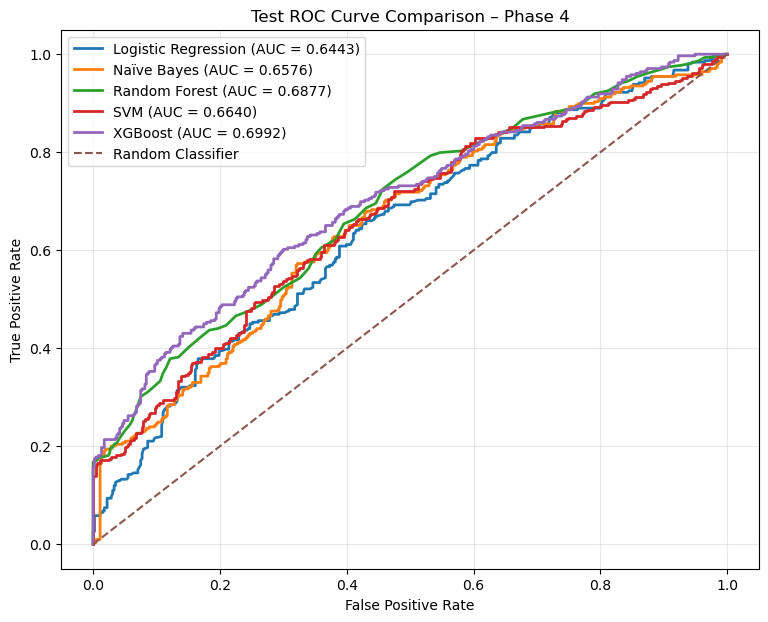

Test AUC values:
Logistic Regression: 0.6443
Naïve Bayes:         0.6576
Random Forest:       0.6877
SVM:                 0.6640
XGBoost:             0.6992


In [ ]:
# Phase 4 - Test ROC Curve Comparison
# Calculate all ROC curves directly from the test-set probabilities.

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# ---------------------------------------------------------
# Logistic Regression
# ---------------------------------------------------------
y_test_prob_logit = reduced_result.predict(
    X_test_reduced_sm
)

fpr_logit, tpr_logit, _ = roc_curve(
    y_test,
    y_test_prob_logit
)

auc_logit = roc_auc_score(
    y_test,
    y_test_prob_logit
)

# ---------------------------------------------------------
# Naïve Bayes
# ---------------------------------------------------------
fpr_nb, tpr_nb, _ = roc_curve(
    y_test,
    y_test_prob_nb
)

auc_nb = roc_auc_score(
    y_test,
    y_test_prob_nb
)

# ---------------------------------------------------------
# Random Forest
# ---------------------------------------------------------
fpr_rf, tpr_rf, _ = roc_curve(
    y_test,
    y_test_prob_rf
)

auc_rf = roc_auc_score(
    y_test,
    y_test_prob_rf
)

# ---------------------------------------------------------
# SVM
# ---------------------------------------------------------
fpr_svm, tpr_svm, _ = roc_curve(
    y_test,
    y_test_prob_svm
)

auc_svm = roc_auc_score(
    y_test,
    y_test_prob_svm
)

# ---------------------------------------------------------
# XGBoost
# ---------------------------------------------------------
fpr_xgb, tpr_xgb, _ = roc_curve(
    y_test,
    y_test_prob_xgb
)

auc_xgb = roc_auc_score(
    y_test,
    y_test_prob_xgb
)

# ---------------------------------------------------------
# Plot all test ROC curves
# ---------------------------------------------------------
plt.figure(figsize=(9, 7))

plt.plot(
    fpr_logit,
    tpr_logit,
    linewidth=2,
    label=f"Logistic Regression (AUC = {auc_logit:.4f})"
)

plt.plot(
    fpr_nb,
    tpr_nb,
    linewidth=2,
    label=f"Naïve Bayes (AUC = {auc_nb:.4f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    linewidth=2,
    label=f"Random Forest (AUC = {auc_rf:.4f})"
)

plt.plot(
    fpr_svm,
    tpr_svm,
    linewidth=2,
    label=f"SVM (AUC = {auc_svm:.4f})"
)

plt.plot(
    fpr_xgb,
    tpr_xgb,
    linewidth=2,
    label=f"XGBoost (AUC = {auc_xgb:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Curve Comparison – Phase 4")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Print the AUC values used in the chart
print("Test AUC values:")
print(f"Logistic Regression: {auc_logit:.4f}")
print(f"Naïve Bayes:         {auc_nb:.4f}")
print(f"Random Forest:       {auc_rf:.4f}")
print(f"SVM:                 {auc_svm:.4f}")
print(f"XGBoost:             {auc_xgb:.4f}")

In [ ]:
print("Features used by the current split:")
print(X_train.columns.tolist())

print("\nData types:")
print(X_train.dtypes)

Features used by the current split:
['Recency', 'Frequency', 'Monetary', 'TotalQuantity', 'AvgUnitPrice', 'UniqueProducts', 'n_comp', 'n_communications', 'loyalty', 'NPS_Passive', 'NPS_Promoter']

Data types:
Recency             int64
Frequency           int64
Monetary            int64
TotalQuantity       int64
AvgUnitPrice        int64
UniqueProducts      int64
n_comp              int64
n_communications    int64
loyalty             int64
NPS_Passive         int64
NPS_Promoter        int64
dtype: object


In [ ]:
# Phase 4 final validation check

print("Final modelling dataset:", model_df.shape)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nFinal test AUCs:")
print(f"Logistic Regression: {auc_test:.4f}")
print(f"Naïve Bayes:         {nb_test_auc:.4f}")
print(f"Random Forest:       {rf_test_auc:.4f}")
print(f"SVM:                 {svm_test_auc:.4f}")
print(f"XGBoost:             {auc_test_xgb:.4f}")

print("\nShape checks:")

expected_model_shape = (3809, 8)
expected_train_shape = (3047, 7)
expected_test_shape = (762, 7)

print(
    "model_df:",
    "PASS" if model_df.shape == expected_model_shape else f"CHECK - got {model_df.shape}"
)

print(
    "X_train:",
    "PASS" if X_train.shape == expected_train_shape else f"CHECK - got {X_train.shape}"
)

print(
    "X_test:",
    "PASS" if X_test.shape == expected_test_shape else f"CHECK - got {X_test.shape}"
)

Final modelling dataset: (3809, 8)
Training set: (3047, 8)
Test set: (762, 8)

Final test AUCs:
Logistic Regression: 0.6443
Naïve Bayes:         0.6576
Random Forest:       0.6877
SVM:                 0.6640
XGBoost:             0.6992

Shape checks:
model_df: PASS
X_train: CHECK - got (3047, 8)
X_test: CHECK - got (762, 8)
